# Proyecto EDA

## 1. Carga y unión de datos

In [163]:
# IMPORTACIÓN DE LIBRERIAS NECESARIAS PARA EL PROYECTO

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

print('Entorno configurado y librerías instaladas con éxito')

Entorno configurado y librerías instaladas con éxito


In [164]:
# Configuración de la visualización de pandas
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

### 1.1. Carga de los datasets originales
A continuación, procedemos a importar los datos en bruto desde nuestra carpeta `data/raw/`. 
Cargaremos el archivo CSV de campañas de marketing y las diferentes hojas del archivo Excel de detalles de clientes.

In [165]:
ruta_csv = '../data/raw/bank-additional.csv'
df_banco = pd.read_csv(ruta_csv)
df_banco.head()

,Unnamed: 0,age,job,marital,education,default,housing,loan,contact,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,date,latitude,longitude,id_
0,0,NaN,housemaid,MARRIED,basic.4y,0.0,0.0,0.0,telephone,261,1,999,0,NONEXISTENT,1.1,"93,994","-36,4","4,857",5191,no,2-agosto-2019,41.495,-71.233,089b39d8-e4d0-461b-87d4-814d71e0e079
1,1,57.0,services,MARRIED,high.school,NaN,0.0,0.0,telephone,149,1,999,0,NONEXISTENT,1.1,"93,994","-36,4",NaN,5191,no,14-septiembre-2016,34.601,-83.923,e9d37224-cb6f-4942-98d7-46672963d097
2,2,37.0,services,MARRIED,high.school,0.0,1.0,0.0,telephone,226,1,999,0,NONEXISTENT,1.1,"93,994","-36,4","4,857",5191,no,15-febrero-2019,34.939,-94.847,3f9f49b5-e410-4948-bf6e-f9244f04918b
3,3,40.0,admin.,MARRIED,basic.6y,0.0,0.0,0.0,telephone,151,1,999,0,NONEXISTENT,1.1,"93,994","-36,4",NaN,5191,no,29-noviembre-2015,49.041,-70.308,9991fafb-4447-451a-8be2-b0df6098d13e
4,4,56.0,services,MARRIED,high.school,0.0,0.0,1.0,telephone,307,1,999,0,NONEXISTENT,1.1,"93,994","-36,4",NaN,5191,no,29-enero-2017,38.033,-104.463,eca60b76-70b6-4077-80ba-bc52e8ebb0eb


In [166]:
# cargamos el dataset del archivo excel

ruta_excel = '../data/raw/customer-details.xlsx'

#nos traemos las 3 hojas de las que se compone el excel
df_2012 = pd.read_excel(ruta_excel, sheet_name='2012')
df_2013 = pd.read_excel(ruta_excel, sheet_name='2013')
df_2014 = pd.read_excel(ruta_excel, sheet_name='2014')

# concatenamos las 3 hojas del excel en un solo dataframe
df_clientes = pd.concat([df_2012,df_2013,df_2014], ignore_index = True)

df_clientes.head()

,Unnamed: 0,Income,Kidhome,Teenhome,Dt_Customer,NumWebVisitsMonth,ID
0,0,161770,1,0,2012-04-04,29,089b39d8-e4d0-461b-87d4-814d71e0e079
1,1,85477,1,1,2012-12-30,7,e9d37224-cb6f-4942-98d7-46672963d097
2,2,147233,1,1,2012-02-02,5,3f9f49b5-e410-4948-bf6e-f9244f04918b
3,3,121393,1,2,2012-12-21,29,9991fafb-4447-451a-8be2-b0df6098d13e
4,4,63164,1,2,2012-06-20,20,eca60b76-70b6-4077-80ba-bc52e8ebb0eb


### 1.2 Verificado de unión

Comprobamos que la concatenación de las 3 hojas ha sido la correcta. Realizamos una suma de las 3 hojas para ver si el núemro conicide con el total de registros del nuevo datafreame que hemos creado 'df_clientes'.

In [167]:
print(f'Clientes en 2012: {len(df_2012)}')
print(f'Clientes en 2013: {len(df_2013)}')
print(f'Clientes en 2014: {len(df_2014)}')
print(f'Suma de  las 3 hojas: {(len(df_2012) + (len(df_2013)) + (len(df_2014)))}')
print('-----------------------------------')
print(f'Total de clientes fusionados: {len(df_clientes)}')

Clientes en 2012: 20115
Clientes en 2013: 8965
Clientes en 2014: 14090
Suma de  las 3 hojas: 43170
-----------------------------------
Total de clientes fusionados: 43170


### 1.3 Identificación columnas

Comprobamos las columnas de los dos dataframe para comprobar a través de que columna se pueden unir.

In [168]:
print('Variables en el dataset de Campañas (df_banco):')
print(df_banco.columns.tolist())
print('--------------------------------------------------')
print('Variables en el dataset de Clientes (df_clientes):')
print(df_clientes.columns.tolist())

Variables en el dataset de Campañas (df_banco):
['Unnamed: 0', 'age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y', 'date', 'latitude', 'longitude', 'id_']
--------------------------------------------------
Variables en el dataset de Clientes (df_clientes):
['Unnamed: 0', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'NumWebVisitsMonth', 'ID']


Como se puede observar, los dos dataframes tienen una columna ID, aunque están escritas diferentes, en 'df_banco' aparece como 'id_' y en 'df_clientes' aparece como 'ID', a continuación comprobamos el aspecto de los registros para saber si se trata de lo mismo. También se puede observar que hay dos columnas llamadas 'Unnamed: 0', que las trataremos psoteriormente en la limpieza del dataset.

In [169]:
# Vemos los 5 últimos IDs de cada tabla para inspeccionar su formato real
print('Muestra de id_ en df_banco:')
print(df_banco['id_'].tail())

print('\nMuestra de ID en df_clientes:')
print(df_clientes['ID'].tail())

Muestra de id_ en df_banco:
42995    4eed05de-2a98-4227-b488-32122009b638
42996    0f0aca88-4088-4fe2-905f-44fb675d9493
42997    cadadd4b-7ee5-4019-b13a-ca01bb67ca5b
42998    5f432048-d515-4bb5-9c94-62db451f88d4
42999    993bbbd6-4dbc-4a40-a408-f91f8462bee6
Name: id_, dtype: str

Muestra de ID en df_clientes:
43165    5f432048-d515-4bb5-9c94-62db451f88d4
43166    993bbbd6-4dbc-4a40-a408-f91f8462bee6
43167    d6271666-319d-42c8-a741-cb22bf2c2093
43168    f67fbfa8-6573-414d-a805-b26a2f1b1ceb
43169    9727bc06-c11a-461a-a5bb-3d210467cc2a
Name: ID, dtype: str


La comprobación es positiva ya que las dos columnas tienen el mismo tipo de información y por lo tanto, podemos unir los dos dataframes

### 1.4 Unión de los dos dataframes

In [170]:
#unimos los dos dataframes a partir de un merge le llamaremos df_bc (abreviación de banco-cliente)

df_bc = pd.merge(df_banco,df_clientes, left_on = 'id_', right_on = 'ID', how= 'inner')
df_bc.info()

<class 'pandas.DataFrame'>
RangeIndex: 43000 entries, 0 to 42999
Data columns (total 31 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Unnamed: 0_x       43000 non-null  int64         
 1   age                37880 non-null  float64       
 2   job                42655 non-null  str           
 3   marital            42915 non-null  str           
 4   education          41193 non-null  str           
 5   default            34019 non-null  float64       
 6   housing            41974 non-null  float64       
 7   loan               41974 non-null  float64       
 8   contact            43000 non-null  str           
 9   duration           43000 non-null  int64         
 10  campaign           43000 non-null  int64         
 11  pdays              43000 non-null  int64         
 12  previous           43000 non-null  int64         
 13  poutcome           43000 non-null  str           
 14  emp.var.rate     

Si nos fijamos, el dataset de clientes tenía 43.170 filas y el resultado final nos da exactamente 43.000. Esto significa que nos hemos dejado fuera a 170 clientes.
Esto pasa porque hemos usado inner join para juntar los registros que están en las dos tablas a la vez. 



Esos 170 clientes están en la base de datos general, pero nunca se les llegó a llamar en esta campaña de marketing (no existen en df_banco). Al no tener datos de sus llamadas ni de si compraron el producto, no los necesitamos para el posteriror análisis.

La unión de los dos dataframes ha sido satisfactoría y ya se puede pasar a trabajar con la limpieza.

## 2. Inspección del dataset

### 2.1 Dimensiones del dataset

In [171]:
#dimensiones del dataset filas y columnas
df_bc.shape

(43000, 31)

El conjunto de datos está formado por 43000 registros y 31 variables, lo que nos da una primera idea del tamaño del dataset sobre el que vamos a trabajar.

### 2.2 Aspecto del dataset

In [172]:
#primeras filas del datset
df_bc.head()

,Unnamed: 0_x,age,job,marital,education,default,housing,loan,contact,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,date,latitude,longitude,id_,Unnamed: 0_y,Income,Kidhome,Teenhome,Dt_Customer,NumWebVisitsMonth,ID
0,0,NaN,housemaid,MARRIED,basic.4y,0.0,0.0,0.0,telephone,261,1,999,0,NONEXISTENT,1.1,"93,994","-36,4","4,857",5191,no,2-agosto-2019,41.495,-71.233,089b39d8-e4d0-461b-87d4-814d71e0e079,0,161770,1,0,2012-04-04,29,089b39d8-e4d0-461b-87d4-814d71e0e079
1,1,57.0,services,MARRIED,high.school,NaN,0.0,0.0,telephone,149,1,999,0,NONEXISTENT,1.1,"93,994","-36,4",NaN,5191,no,14-septiembre-2016,34.601,-83.923,e9d37224-cb6f-4942-98d7-46672963d097,1,85477,1,1,2012-12-30,7,e9d37224-cb6f-4942-98d7-46672963d097
2,2,37.0,services,MARRIED,high.school,0.0,1.0,0.0,telephone,226,1,999,0,NONEXISTENT,1.1,"93,994","-36,4","4,857",5191,no,15-febrero-2019,34.939,-94.847,3f9f49b5-e410-4948-bf6e-f9244f04918b,2,147233,1,1,2012-02-02,5,3f9f49b5-e410-4948-bf6e-f9244f04918b
3,3,40.0,admin.,MARRIED,basic.6y,0.0,0.0,0.0,telephone,151,1,999,0,NONEXISTENT,1.1,"93,994","-36,4",NaN,5191,no,29-noviembre-2015,49.041,-70.308,9991fafb-4447-451a-8be2-b0df6098d13e,3,121393,1,2,2012-12-21,29,9991fafb-4447-451a-8be2-b0df6098d13e
4,4,56.0,services,MARRIED,high.school,0.0,0.0,1.0,telephone,307,1,999,0,NONEXISTENT,1.1,"93,994","-36,4",NaN,5191,no,29-enero-2017,38.033,-104.463,eca60b76-70b6-4077-80ba-bc52e8ebb0eb,4,63164,1,2,2012-06-20,20,eca60b76-70b6-4077-80ba-bc52e8ebb0eb


Se visualizan las primeras filas para comprobar la estructura del dataset y verificar que la unión de los datos se ha realizado correctamente.

### 2.3 Información general 

In [173]:
#información general del dataset
df_bc.info()

<class 'pandas.DataFrame'>
RangeIndex: 43000 entries, 0 to 42999
Data columns (total 31 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Unnamed: 0_x       43000 non-null  int64         
 1   age                37880 non-null  float64       
 2   job                42655 non-null  str           
 3   marital            42915 non-null  str           
 4   education          41193 non-null  str           
 5   default            34019 non-null  float64       
 6   housing            41974 non-null  float64       
 7   loan               41974 non-null  float64       
 8   contact            43000 non-null  str           
 9   duration           43000 non-null  int64         
 10  campaign           43000 non-null  int64         
 11  pdays              43000 non-null  int64         
 12  previous           43000 non-null  int64         
 13  poutcome           43000 non-null  str           
 14  emp.var.rate     

Tras la unión de ambos conjuntos de datos se obtiene un dataframe compuesto por 43.000 registros y 31 variables, combinando información demográfica, financiera y de las campañas de marketing del banco.

La inspección inicial permite detectar varios aspectos que deberán tratarse durante la fase de limpieza:

- Existen columnas auxiliares (Unnamed: 0_x y Unnamed: 0_y) generadas durante la exportación de los archivos, que no aportan información al análisis.

- Algunas variables numéricas (cons.price.idx, cons.conf.idx, euribor3m y nr.employed) aparecen almacenadas como texto y deberán convertirse al tipo de dato adecuado.

- Se observan valores nulos en variables como age, education, default, housing, loan, euribor3m o date, por lo que será necesario evaluar el tratamiento más adecuado para cada caso antes de comenzar el análisis exploratorio.

### 2.4 Resumen estadístico

En primer lugar, se realiza un análisis descriptivo diferenciando las variables almacenadas como numéricas y las almacenadas como texto. No obstante, algunas variables numéricas (`default`, `housing`, `loan`, `Kidhome` y `Teenhome`) representan categorías y serán analizadas posteriormente como variables categóricas.

#### Variables numéricas

In [174]:
var_num = [
    'age',
    'duration',
    'campaign',
    'pdays',
    'previous',
    'emp.var.rate',
    'cons.price.idx',
    'cons.conf.idx',
    'euribor3m',
    'nr.employed',
    'Income',
    'NumWebVisitsMonth'
]

In [175]:
df_bc[var_num].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,37880.0,39.98,10.44,17.0,32.0,38.0,47.0,98.0
duration,43000.0,257.74,258.67,0.0,102.0,179.0,319.0,4918.0
campaign,43000.0,2.57,2.77,1.0,1.0,2.0,3.0,56.0
pdays,43000.0,962.33,187.26,0.0,999.0,999.0,999.0,999.0
previous,43000.0,0.17,0.50,0.0,0.0,0.0,0.0,7.0
emp.var.rate,43000.0,0.08,1.57,-3.4,-1.8,1.1,1.4,1.4
Income,43000.0,93241.20,50498.32,5841.0,49610.0,93050.5,136744.5,180802.0
NumWebVisitsMonth,43000.0,16.59,9.24,1.0,9.0,17.0,25.0,32.0


##### Descripción de las variables numéricas

- `age`: La edad de los clientes va desde los **17 hasta los 98 años**, con una media de **39,75 años**. La media y la mediana (38 años) son muy parecidas, lo que indica que la mayoría de clientes se concentra alrededor de esas edades. A simple vista no se observan valores que parezcan errores o imposibles.

- `duration`: La duración de las llamadas oscila entre **0 y 4.918 segundos**, con una media de **257,74 segundos**. Existe una gran diferencia entre el valor mínimo y el máximo, por lo que será interesante comprobar más adelante si esas llamadas tan largas corresponden a valores atípicos o forman parte del comportamiento normal del conjunto de datos.

- `campaign`: El número de contactos realizados durante la campaña va desde **1 hasta 56**, siendo lo más habitual realizar entre **1 y 3 contactos** por cliente. El valor máximo llama la atención, ya que contactar tantas veces con un mismo cliente no parece lo más habitual y será interesante analizarlo con más detalle.

- `pdays`: Esta variable representa los días transcurridos desde el último contacto con el cliente. La mediana y el tercer cuartil toman el valor **999**, que según la documentación del dataset indica que el cliente **no había sido contactado anteriormente**. Por tanto, este valor no debe interpretarse como un error.

- `previous`: El número de contactos realizados en campañas anteriores va desde **0 hasta 7**. La mayoría de clientes presenta un valor de **0**, lo que indica que no habían participado en campañas anteriores. A simple vista no se observan valores que llamen especialmente la atención.

- `emp.var.rate`: La tasa de variación del empleo toma valores entre **-3,4 y 1,4**. Al tratarse de un indicador económico, los valores observados parecen normales y no se aprecia ningún dato extraño.

- `cons.price.idx`: El índice de precios al consumidor presenta valores entre **92,20 y 94,77**, con muy poca variación entre registros. Esto es normal al tratarse de un indicador económico y no se observan valores fuera de lo esperado.

- `cons.conf.idx`: El índice de confianza del consumidor varía entre **-50,8 y -26,9**. Todos los valores son negativos, algo habitual en este tipo de indicador, por lo que no se aprecia ningún dato extraño.

- `euribor3m`: El Euribor a tres meses oscila entre **0,63 y 5,04**, un rango coherente con la evolución de este indicador económico. A simple vista no se detectan valores anómalos.

- `nr.employed`: El número de empleados se encuentra entre **4.963,6 y 5.228,1**. La diferencia entre registros es pequeña, algo lógico al tratarse de un indicador económico. No se observan valores que llamen la atención.

- `Income`: Los ingresos anuales de los clientes van desde **5.841 € hasta 180.802 €**, con una media de **93.241 €**. Existe bastante diferencia entre unos clientes y otros, algo normal cuando se trabaja con ingresos. A simple vista no se detectan valores imposibles o incoherentes.

- `NumWebVisitsMonth`: El número de visitas mensuales a la página web oscila entre **1 y 32**, con una media cercana a las **17 visitas al mes**. Aunque algunos clientes visitan la web prácticamente a diario, siguen siendo valores totalmente posibles.

In [176]:
# Copia solo con las variables numéricas ya convertidas (df_bc no se toca)
df_num = pd.DataFrame()
for col in var_num:
    df_num[col] = pd.to_numeric(df_bc[col].astype(str).str.replace(',', '.'), errors='coerce')

##### Histograma

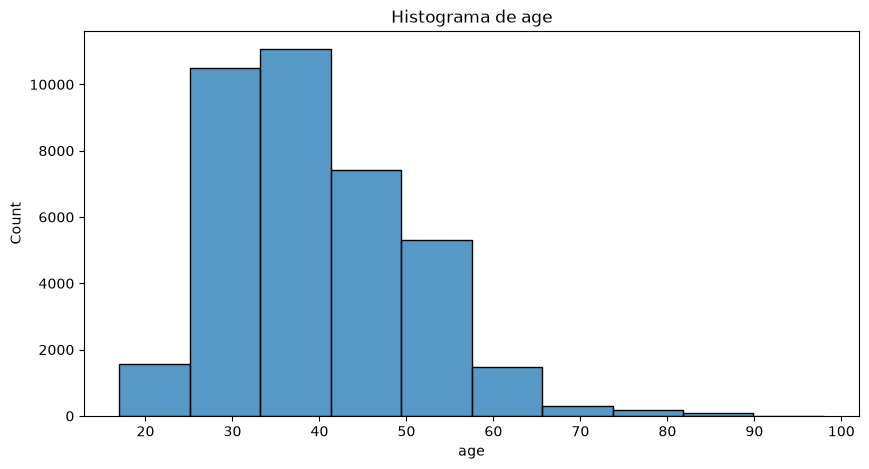

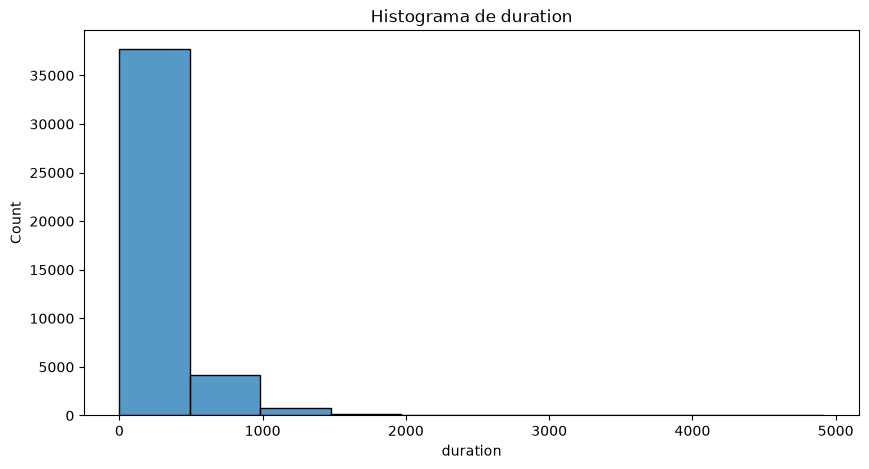

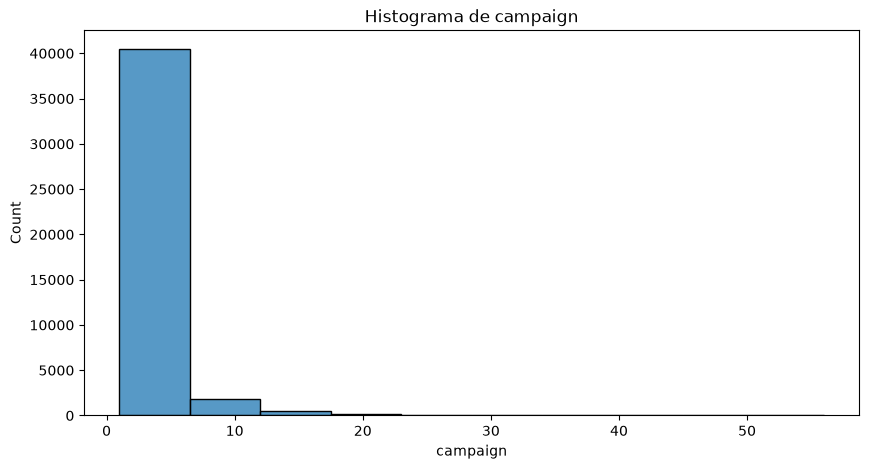

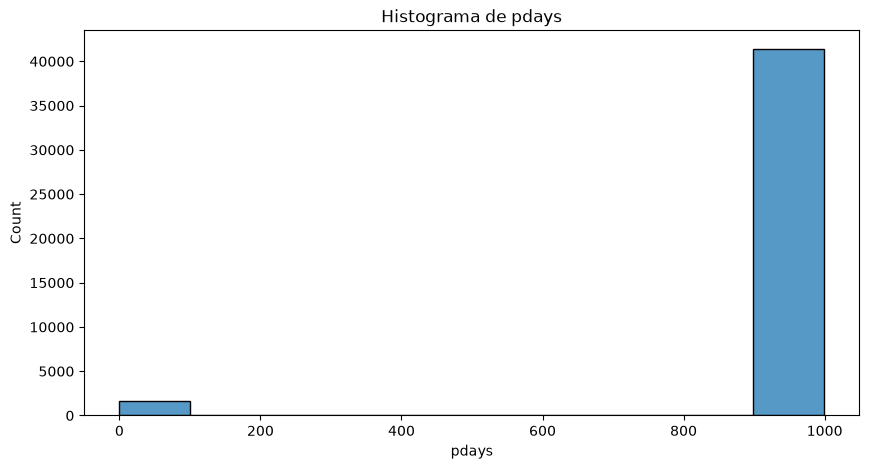

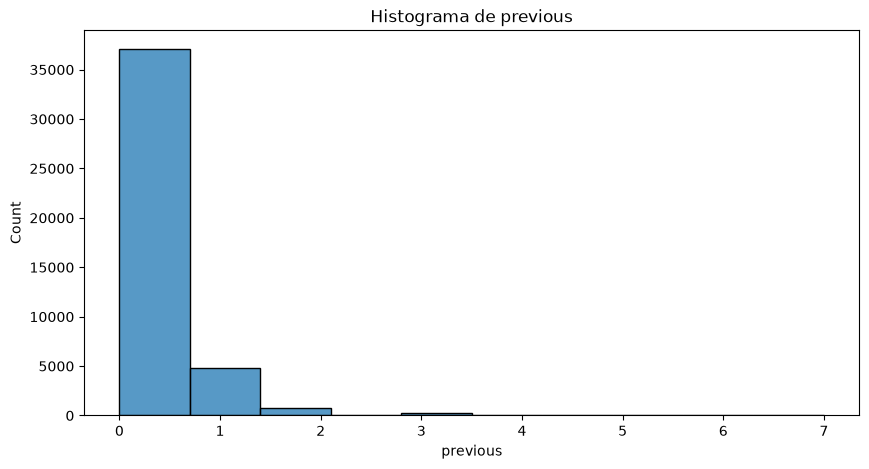

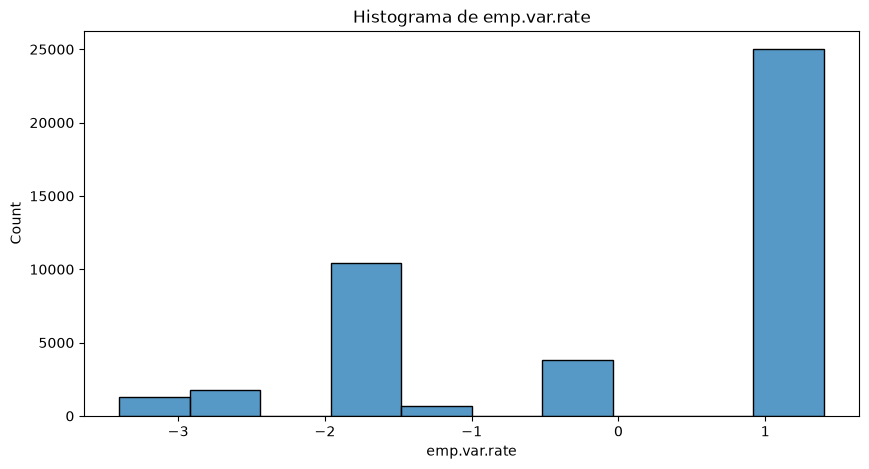

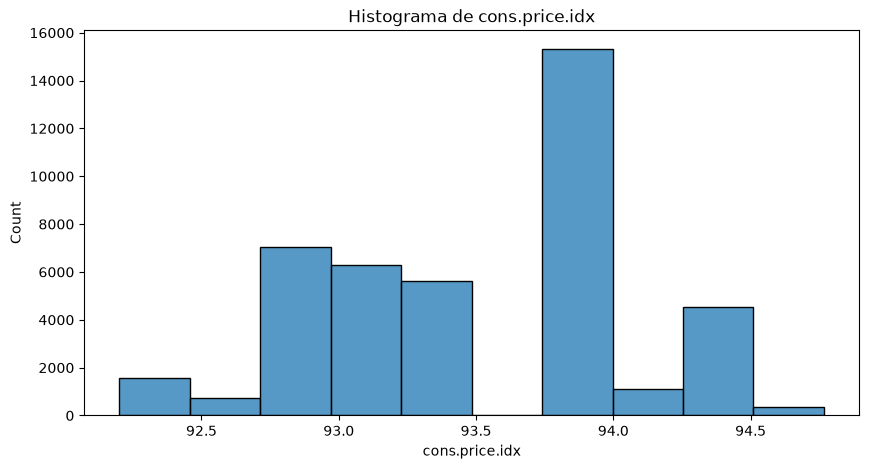

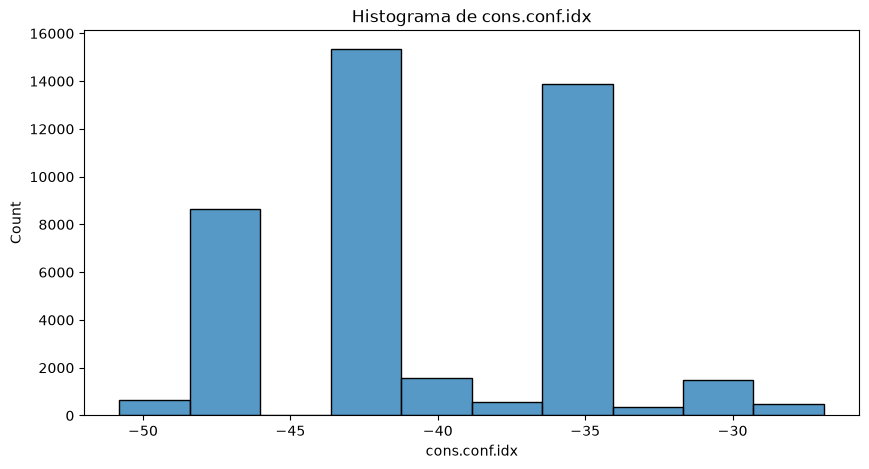

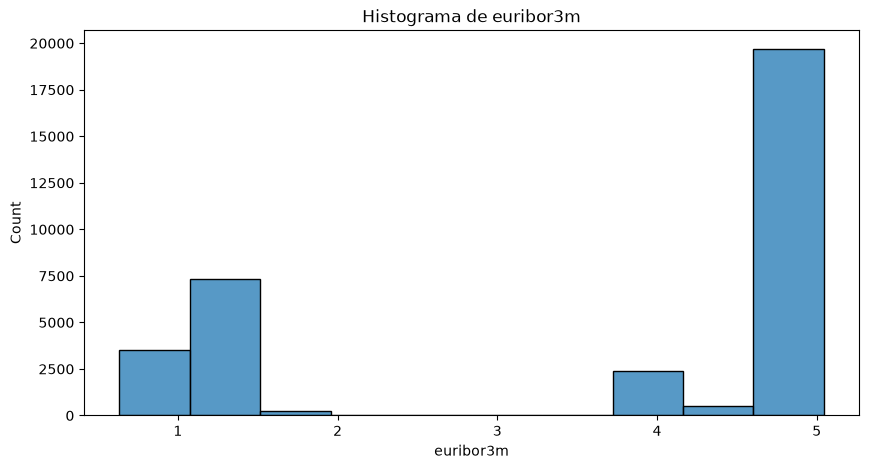

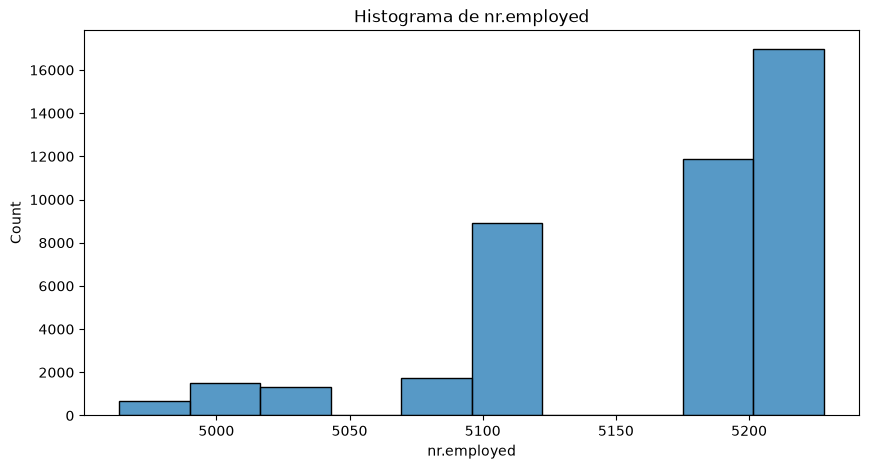

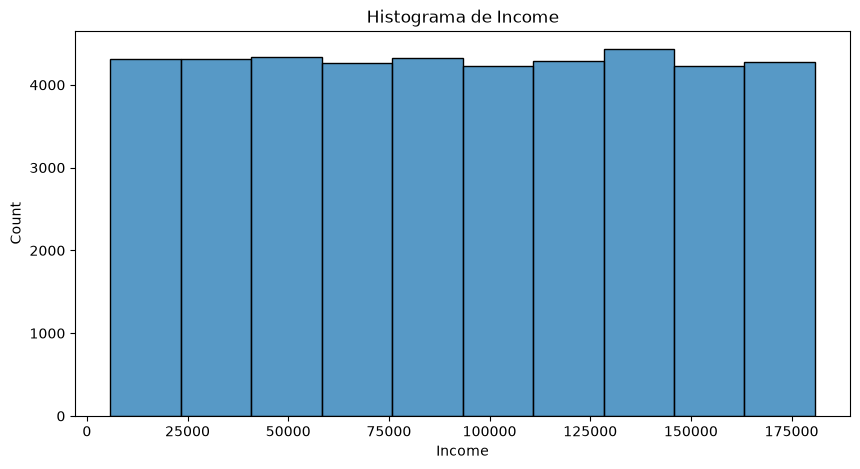

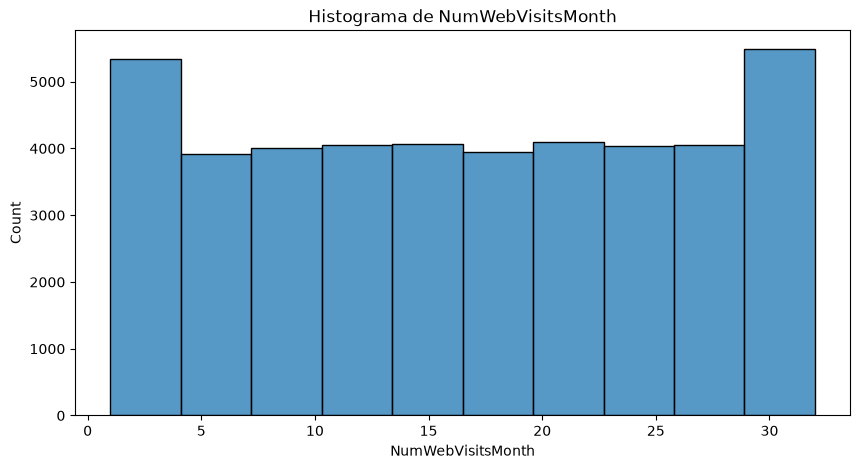

In [177]:
for col in var_num:
    plt.figure(figsize=(10,5))
    sns.histplot(df_num[col], bins=10)
    plt.title(f'Histograma de {col}')
    plt.show()

##### Boxplot

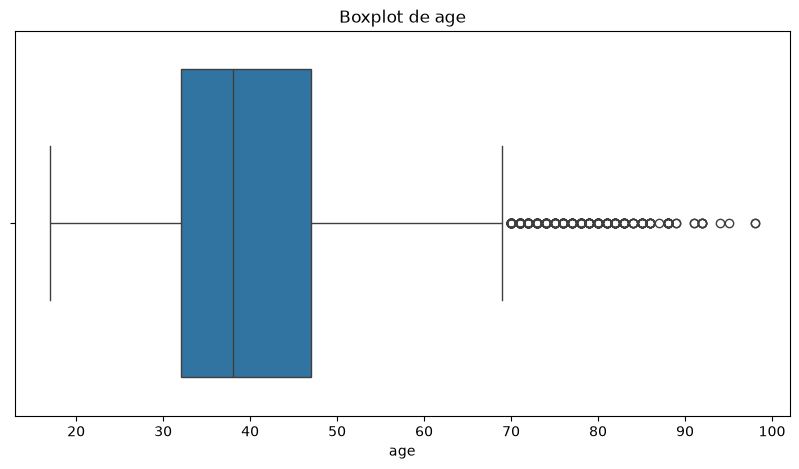

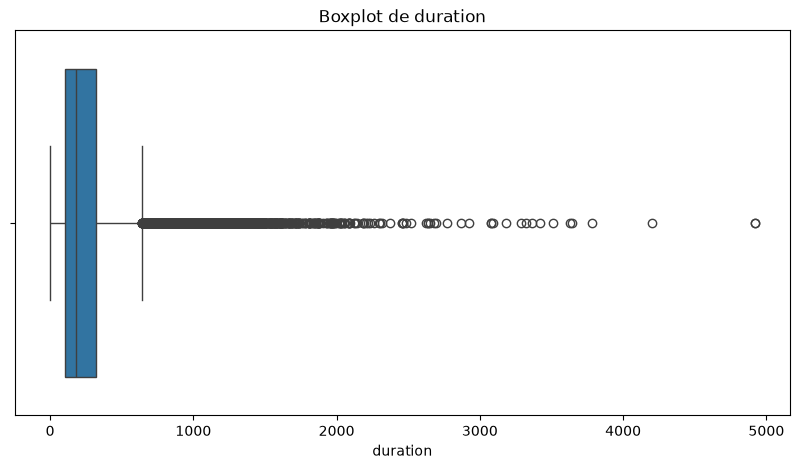

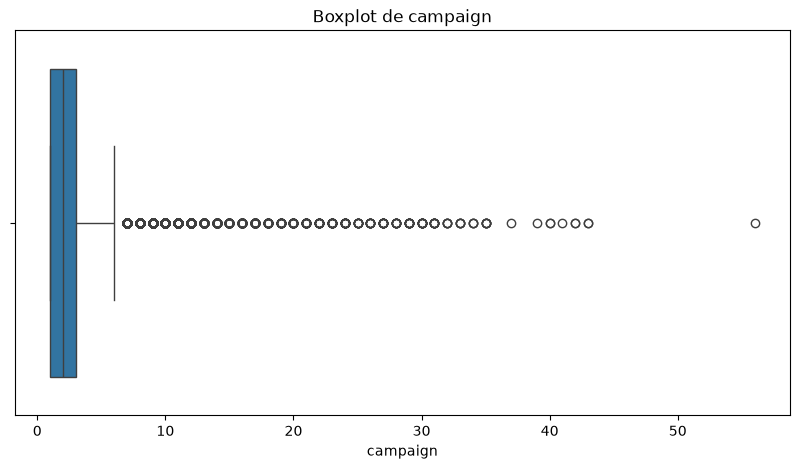

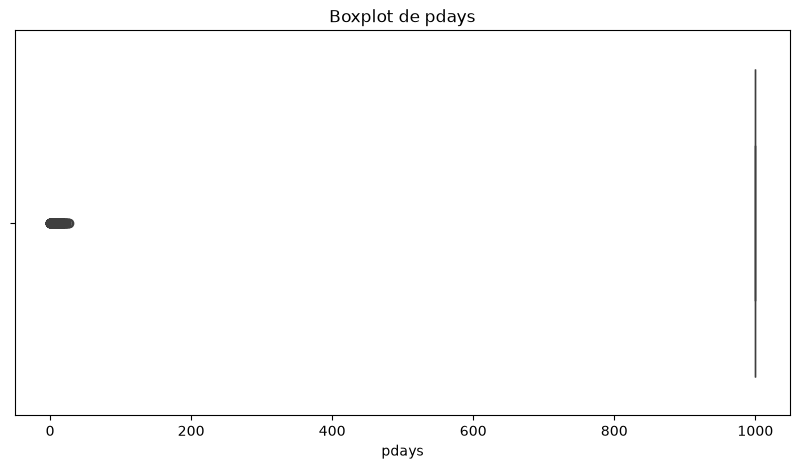

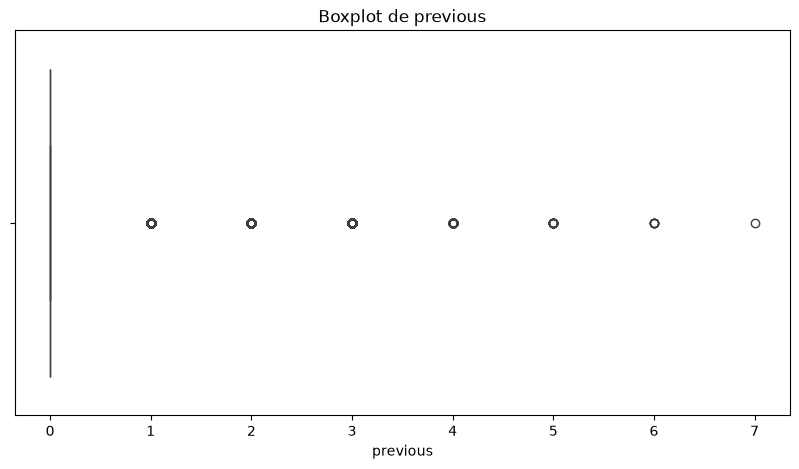

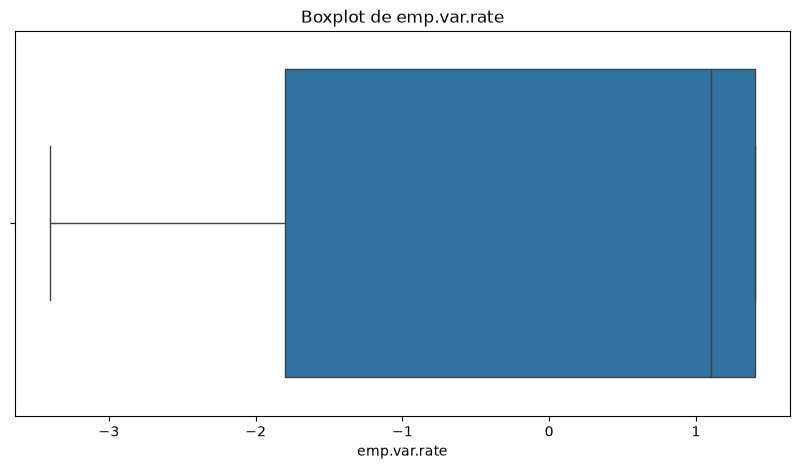

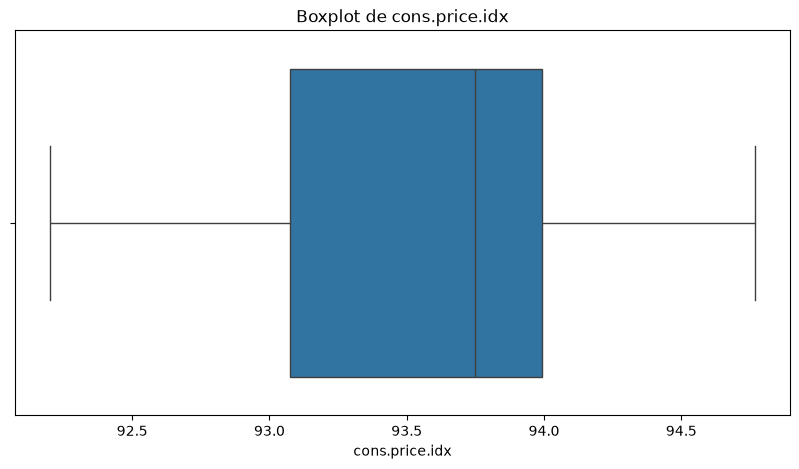

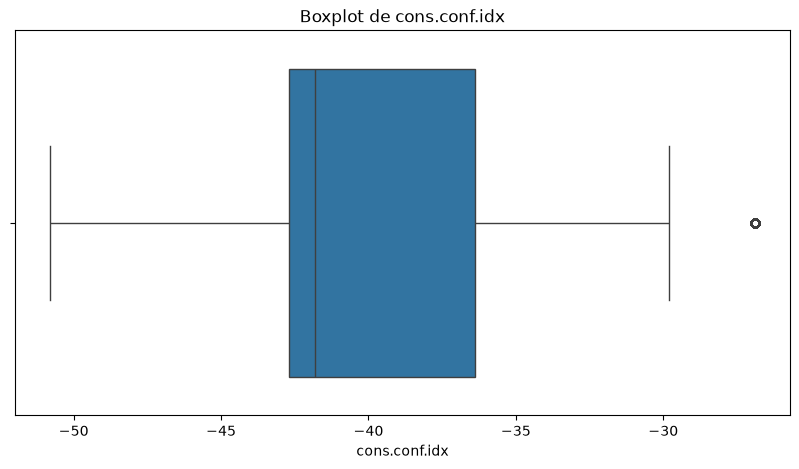

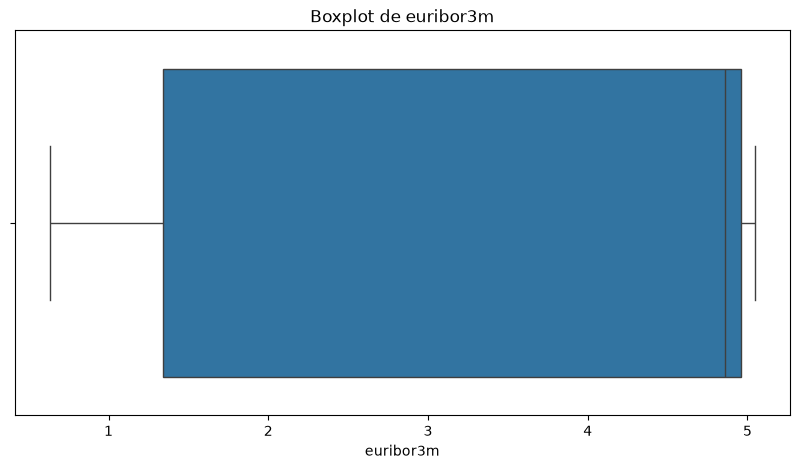

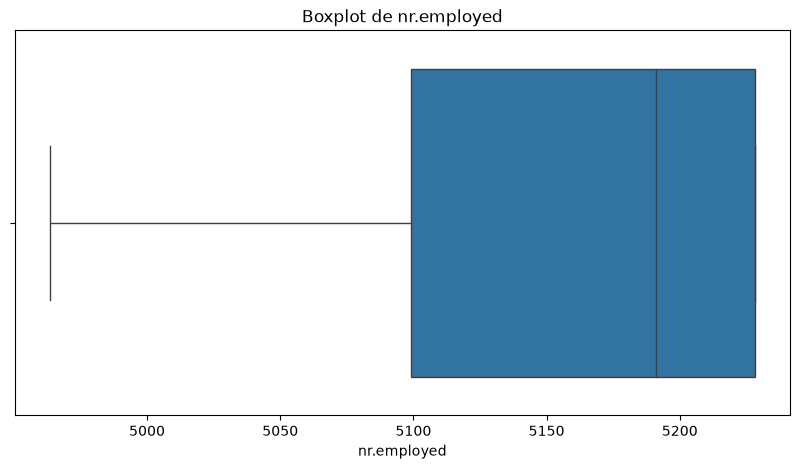

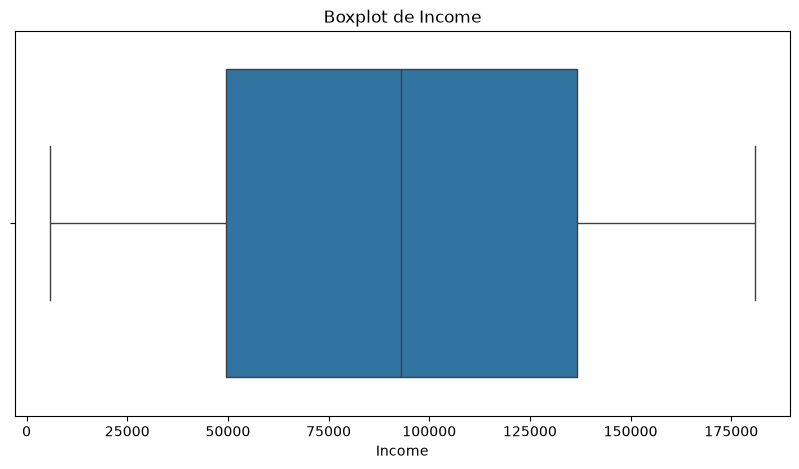

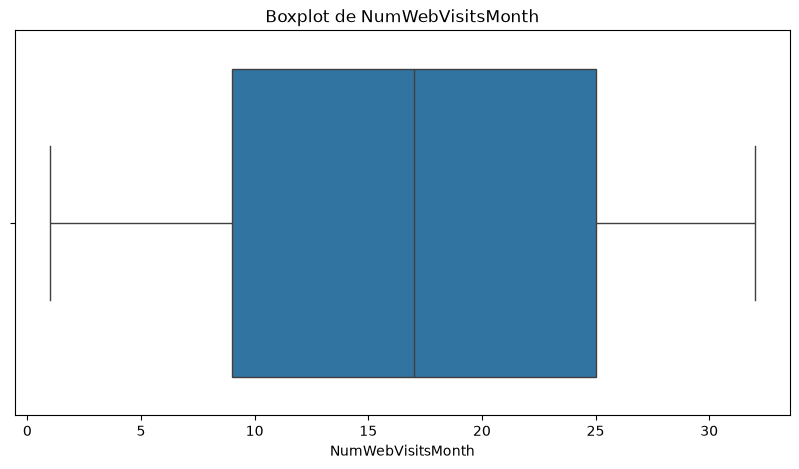

In [178]:
for col in var_num:
    plt.figure(figsize=(10,5))
    sns.boxplot(x=df_num[col])
    plt.title(f'Boxplot de {col}')
    plt.show()

#### Variables categóricas

##### Descripción variables categóricas

Una vez analizadas las variables numéricas, realizamos una primera exploración de las variables categóricas para conocer el número de categorías que presenta cada una de ellas y cuál es la más frecuente en el conjunto de datos.

In [179]:
var_cat = [
    'job',
    'marital',
    'education',
    'default',
    'housing',
    'loan',
    'contact',
    'poutcome',
    'y',
    'Kidhome',
    'Teenhome'
]

In [180]:
df_cat = df_bc[var_cat].copy()
df_cat = df_cat.astype('category')

df_cat.describe().T

,count,unique,top,freq
job,42655,11,admin.,10873
marital,42915,3,MARRIED,25999
education,41193,7,university.degree,12722
default,34019.0,2.0,0.0,34016.0
housing,41974.0,2.0,1.0,22498.0
loan,41974.0,2.0,0.0,35442.0
contact,43000,2,cellular,27396
poutcome,43000,3,NONEXISTENT,37103
y,43000,2,no,38156
Kidhome,43000,3,2,14416


- `job`: La variable recoge **11 profesiones diferentes**, siendo `admin.` la más frecuente con **10.873 clientes**. No se observan categorías fuera de lo esperado, aunque posteriormente será interesante analizar cómo se distribuyen el resto de profesiones.

- `marital`: El estado civil presenta **3 categorías** diferentes, siendo `MARRIED` la más frecuente con **25.999 registros**. La distribución parece coherente para este tipo de población.

- `education`: El nivel educativo contiene **7 categorías**, siendo `university.degree` la más habitual con **13.200 clientes**. A simple vista no se observan categorías extrañas.

- `contact`: El método de contacto únicamente presenta **2 categorías** (`cellular` y `telephone`), predominando claramente el contacto mediante **teléfono móvil (`cellular`)** con **27.396 registros**.

- `poutcome`: Esta variable indica el resultado de la campaña de marketing anterior. Presenta **3 categorías**, siendo `NONEXISTENT` la más frecuente con **37.103 registros**, lo que indica que la mayoría de clientes no había participado en campañas anteriores o no existía un resultado previo registrado.

- `y`: Es la variable objetivo del estudio e indica si el cliente contrató o no el depósito a plazo. Presenta **2 categorías**, predominando claramente la respuesta **`no`** con **38.156 registros**, lo que muestra un conjunto de datos desbalanceado.

- `id_`: Se trata de un identificador único para cada cliente. Presenta **43.000 valores únicos**, por lo que no aporta información útil para el análisis exploratorio y únicamente sirve para identificar cada registro de forma individual.

- `default`: Esta variable indica si el cliente tiene algún historial de incumplimiento de pagos. Presenta **2 categorías**, siendo `0` la más frecuente con **34.016 registros**. Además, es una de las variables con mayor cantidad de valores nulos, por lo que será necesario analizar su tratamiento durante la limpieza.

- `housing`: Indica si el cliente tiene un préstamo hipotecario. Presenta **2 categorías**, siendo `1` la más frecuente con **22.498 registros**. También presenta **1.026 valores nulos**, que serán analizados durante el proceso de limpieza.

- `loan`: Indica si el cliente tiene algún otro tipo de préstamo. Presenta **2 categorías**, siendo `0` la más frecuente con **35.442 registros**. Al igual que `housing`, presenta **1.026 valores nulos**, que serán estudiados durante la limpieza.

- `Kidhome`: Indica el número de niños en el hogar del cliente y presenta **3 categorías (0, 1 y 2)**. La categoría más frecuente es `2`, con **14.416 registros**. No presenta valores nulos.

- `Teenhome`: Indica el número de adolescentes en el hogar del cliente y también presenta **3 categorías (0, 1 y 2)**. La categoría más frecuente es `1`, con **14.370 registros**. No presenta valores nulos.

In [181]:
for col in var_cat:
    print(f'La variable "{col}" tiene un total de {df_bc[col].nunique()} valores distintos\n')

    print(f'{df_bc[col].value_counts()}\n')

La variable "job" tiene un total de 11 valores distintos

job
admin.           10873
blue-collar       9654
technician        7026
services          4162
management        3050
retired           1790
entrepreneur      1522
self-employed     1489
housemaid         1123
unemployed        1063
student            903
Name: count, dtype: int64

La variable "marital" tiene un total de 3 valores distintos

marital
MARRIED     25999
SINGLE      12105
DIVORCED     4811
Name: count, dtype: int64

La variable "education" tiene un total de 7 valores distintos

education
university.degree      12722
high.school             9925
basic.9y                6309
professional.course     5477
basic.4y                4356
basic.6y                2386
illiterate                18
Name: count, dtype: int64

La variable "default" tiene un total de 2 valores distintos

default
0.0    34016
1.0        3
Name: count, dtype: int64

La variable "housing" tiene un total de 2 valores distintos

housing
1.0    22498
0

##### Countplot

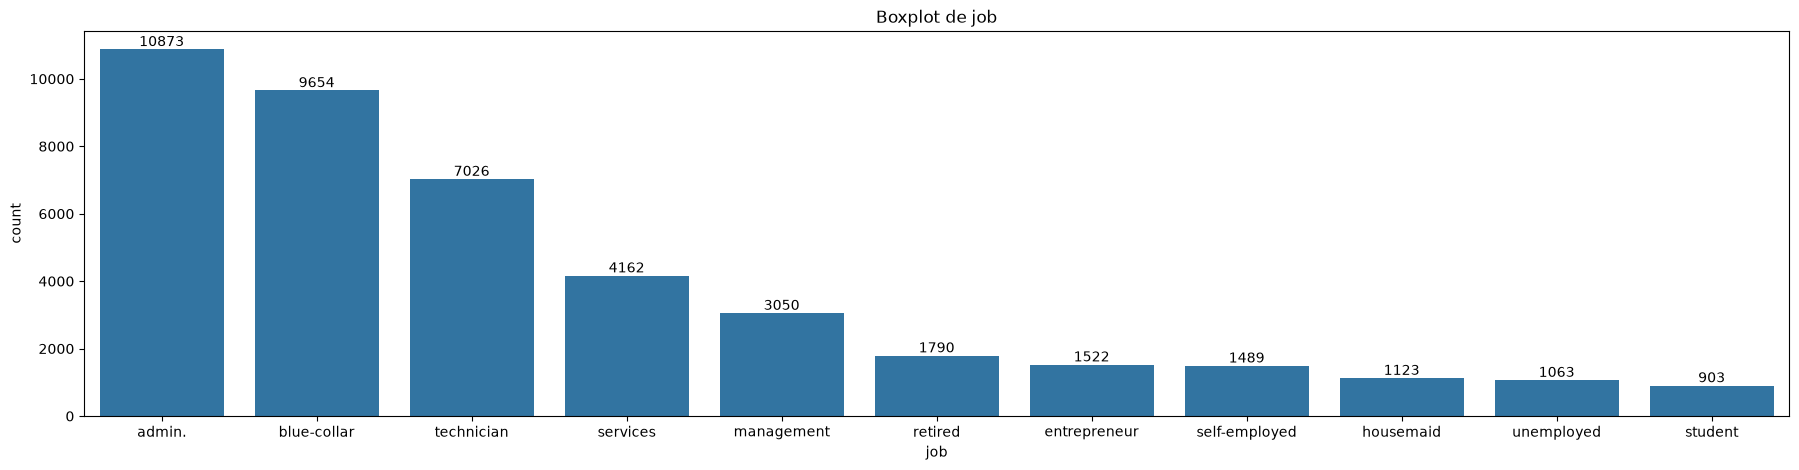

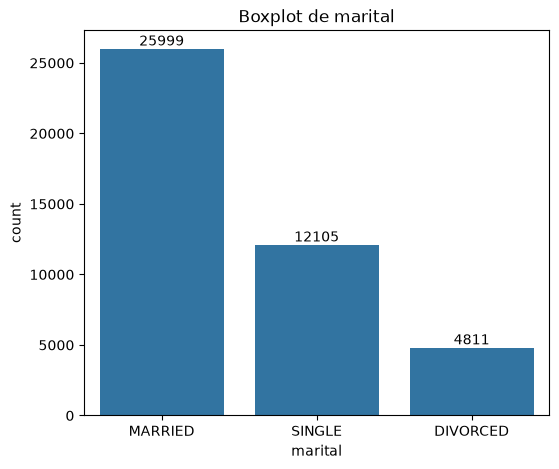

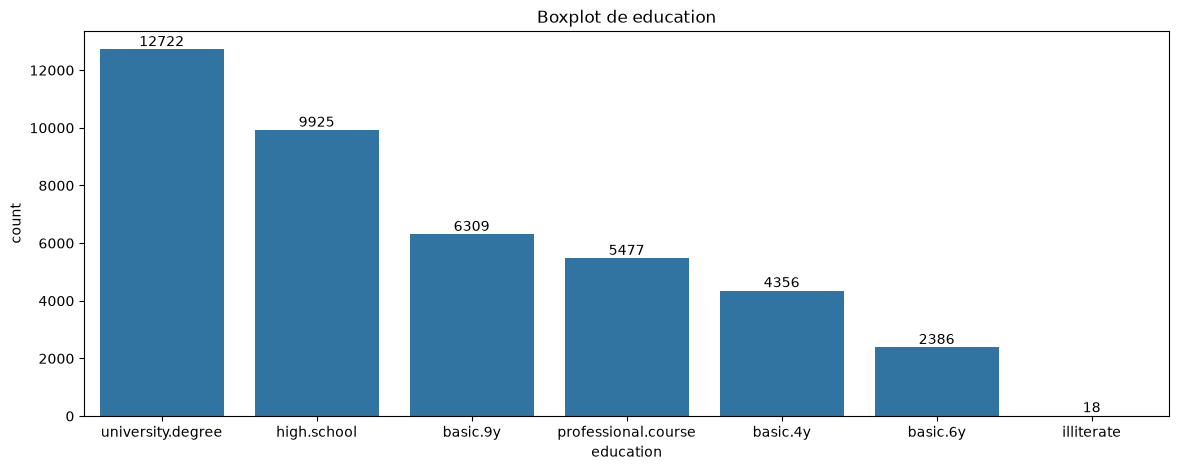

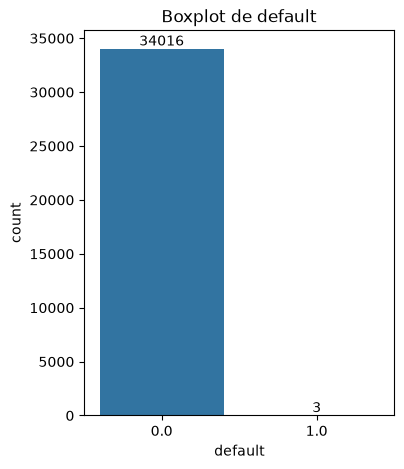

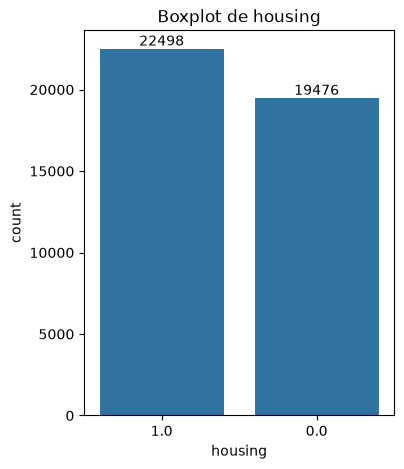

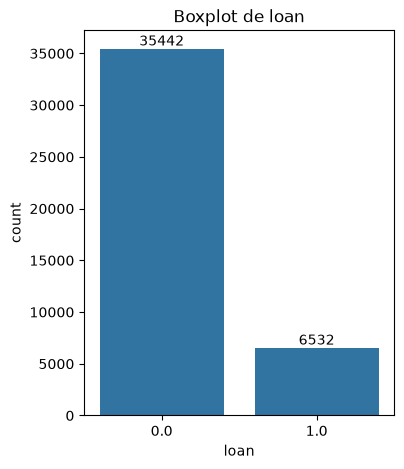

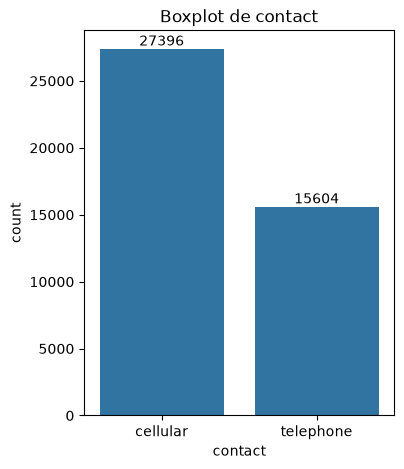

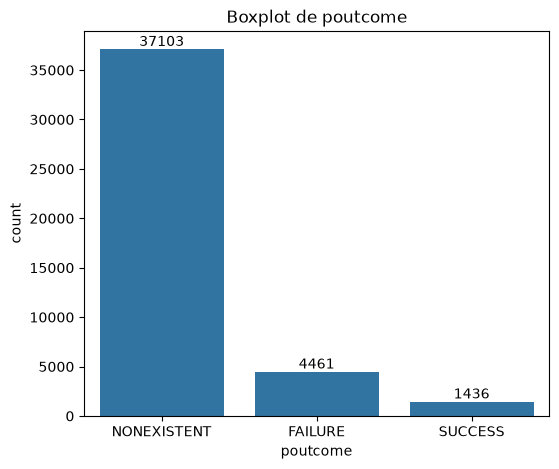

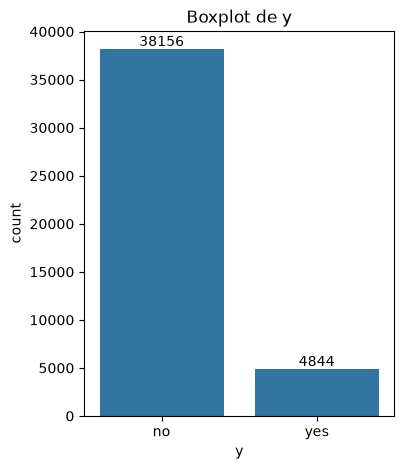

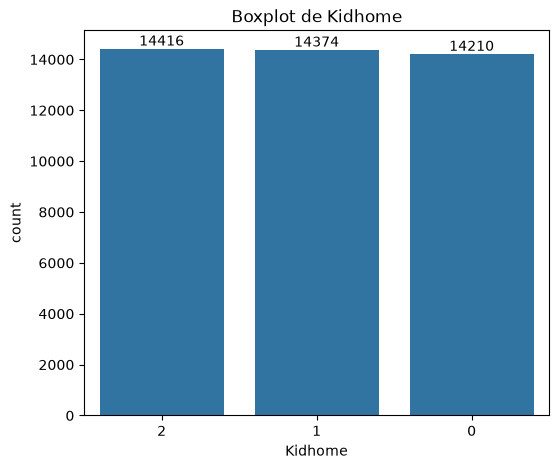

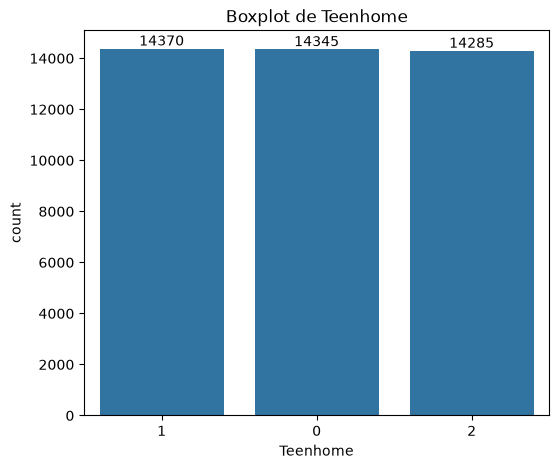

In [182]:
for col in var_cat:
    plt.figure(figsize=(df_bc[col].nunique()*2,5))
    num_var_cat = sns.countplot(data=df_bc,x=col, order=df_bc[col].value_counts().index)
    plt.title(f'Boxplot de {col}')
    for bar in num_var_cat.containers: # número en las barras
        num_var_cat.bar_label(bar)
    plt.show()

En general, las variables categóricas presentan un número reducido de categorías, algo que facilitará su análisis mediante gráficos de barras y tablas de frecuencia. Además, no se observan categorías incoherentes o valores inesperados a simple vista.

## 3. Limpieza y transformación de datos

In [183]:
df_bc.info()

<class 'pandas.DataFrame'>
RangeIndex: 43000 entries, 0 to 42999
Data columns (total 31 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Unnamed: 0_x       43000 non-null  int64         
 1   age                37880 non-null  float64       
 2   job                42655 non-null  str           
 3   marital            42915 non-null  str           
 4   education          41193 non-null  str           
 5   default            34019 non-null  float64       
 6   housing            41974 non-null  float64       
 7   loan               41974 non-null  float64       
 8   contact            43000 non-null  str           
 9   duration           43000 non-null  int64         
 10  campaign           43000 non-null  int64         
 11  pdays              43000 non-null  int64         
 12  previous           43000 non-null  int64         
 13  poutcome           43000 non-null  str           
 14  emp.var.rate     

**Vemos que tenemos un dataframe con 4300 registro y 31 columnas**

se puede observar que al juntarse los dos dataframes, se han modificado los nombres de la columnas 'Unnamed: 0'. Ahora tenemos una llamada 'Unnamed: 0_x' y otra llamada 'Unnamed: 0_y',que son simplemente columnas auxiliares generadas durante la importación, las eliminaremos porque no nos aportan nada al análisis. Tambien, tenemos las dos columnas de ID 'id_' e 'ID' con la misma información, es por eso que nos quedaremos con una sola. También hemos observado que hay dos columnas, 'latitude' y 'longitude' que no sirven para nada y las borraremos.

### 3.1 Reestructuración de columnas

In [184]:
# columnas que queremos eliminar
columnas_drop = ['Unnamed: 0_x', 'Unnamed: 0_y', 'ID','longitude','latitude']


df_bc = df_bc.drop(columns=columnas_drop)

# comprobación de columnas
print(f'Columnas después del drop: {df_bc.shape[1]}')

Columnas después del drop: 26


finalmente, hemos borrado las 5 columnas que no necesitamos y como vemos, se ha pasado de 31 a 26 columnas.

### 3.2 Identifiación de tipo de variables

Una vez limpiadas las columnas que no necesitamos, vamos a ver si nuestras columnas tienen los datos correctos, es decir, si alguna columna que es float debe ser int o si alguna columna que es str debería ser numérica, etc.

In [185]:
df_bc.info()

<class 'pandas.DataFrame'>
RangeIndex: 43000 entries, 0 to 42999
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   age                37880 non-null  float64       
 1   job                42655 non-null  str           
 2   marital            42915 non-null  str           
 3   education          41193 non-null  str           
 4   default            34019 non-null  float64       
 5   housing            41974 non-null  float64       
 6   loan               41974 non-null  float64       
 7   contact            43000 non-null  str           
 8   duration           43000 non-null  int64         
 9   campaign           43000 non-null  int64         
 10  pdays              43000 non-null  int64         
 11  previous           43000 non-null  int64         
 12  poutcome           43000 non-null  str           
 13  emp.var.rate       43000 non-null  float64       
 14  cons.price.idx   

Hemos detectado algunas anomalías en nuestras columnas:

- **age**: tiene el tipo float, debería ser int
- **cons.pricee.idx**: tiene tipo str, debería ser float
- **cons.conf.idx**: tiene tipo str, debería ser float
- **euribor3m**: tiene tipo str, debería ser float
- **nr.employed**: tiene tipo str, debería ser int
- **date**: tiene tipo str, debería ser datetime

también se ha detectado anomalías en las columnas booleanas, pero serán tratadas más adelante. Primero empezaremos por las variables str a float.

#### Transformación de variables str a float

Las variables 'cons.price.idx', 'cons.conf.idx', 'euribor3m' y 'nr.employed' contienen valores numéricos almacenados como texto debido al uso de la coma como separador decimal. Se reemplaza la coma por el punto y posteriormente se convierten a tipo float.

In [186]:
columnas_str_a_float = ['cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

# Reemplazamos la coma por el punto y transformamos a float64
for col in columnas_str_a_float:
    df_bc[col] = pd.to_numeric(df_bc[col].astype(str).str.replace(',', '.'), errors='coerce')

print('Nuevos tipos de datos asignados:')
print(df_bc[columnas_str_a_float].dtypes)

Nuevos tipos de datos asignados:
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
dtype: object


In [187]:
df_bc[['cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']].sample(5)

,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
19493,93.444,-36.1,4.968,5228.1
5490,93.994,-36.4,4.857,5191.0
20249,93.444,-36.1,4.966,5228.1
25442,93.200,-42.0,4.120,5195.8
10550,94.465,-41.8,NaN,5228.1


#### Conversión de variable date a datetime

In [188]:
# Diccionario con los meses en español y su número correspondiente
meses = {
    'enero': '01',
    'febrero': '02',
    'marzo': '03',
    'abril': '04',
    'mayo': '05',
    'junio': '06',
    'julio': '07',
    'agosto': '08',
    'septiembre': '09',
    'octubre': '10',
    'noviembre': '11',
    'diciembre': '12'
}

# Cambiamos el nombre del mes por su número
for mes, numero in meses.items():
    df_bc['date'] = df_bc['date'].str.replace(mes, numero, regex=False)

# Convertimos la columna a formato datetime
df_bc['date'] = pd.to_datetime(df_bc['date'], format='%d-%m-%Y', errors='coerce')

# Comprobamos que la conversión se ha realizado correctamente
print(df_bc['date'].dtype)

df_bc[['date']].head()

datetime64[us]


,date
0,2019-08-02
1,2016-09-14
2,2019-02-15
3,2015-11-29
4,2017-01-29


Se convierte la variable date al tipo datetime para facilitar su manipulación y permitir realizar análisis temporales durante el EDA.

### 3.3 Identificación de duplicados

Vamos a realizar la búsqueda de duplicados, para ver como tratarlos.

In [189]:

total_duplicados = df_bc.duplicated().sum()
print(f'Registros duplicados detectados: {total_duplicados}')

Registros duplicados detectados: 0


Observamos que nuestro dataframe viene sin duplicados.

### 3.4 Inspección de columnas

#### `age`

In [190]:
df_bc['age'].value_counts()

age
31.0    1810
33.0    1704
32.0    1672
36.0    1649
34.0    1608
        ... 
98.0       2
89.0       2
95.0       1
87.0       1
94.0       1
Name: count, Length: 78, dtype: int64

Comprobamos que no tenemos ninguna edad negativa.

In [191]:
df_bc[df_bc['age'] < 0]

,age,job,marital,education,default,housing,loan,contact,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,date,id_,Income,Kidhome,Teenhome,Dt_Customer,NumWebVisitsMonth


In [192]:
df_bc[df_bc['age'] < 18]

,age,job,marital,education,default,housing,loan,contact,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,date,id_,Income,Kidhome,Teenhome,Dt_Customer,NumWebVisitsMonth
36973,17.0,student,SINGLE,NaN,0.0,1.0,0.0,cellular,432,3,4,2,SUCCESS,-2.9,92.201,-31.4,NaN,5076.2,no,2015-12-04,e022180e-6a12-45c8-94ca-f97d3933264c,130645,0,0,2014-07-16,19
37372,17.0,student,SINGLE,basic.9y,0.0,1.0,0.0,cellular,182,2,999,2,FAILURE,-2.9,92.201,-31.4,NaN,5076.2,no,2018-08-26,a1e3729b-2f4a-4784-bb34-ac9f20b30183,61933,0,0,2014-05-10,11
37391,17.0,student,SINGLE,basic.9y,0.0,1.0,0.0,cellular,92,3,4,2,SUCCESS,-2.9,92.201,-31.4,NaN,5076.2,no,2016-12-09,d3a215d5-7238-4c3c-878a-86f8639143c7,70626,0,2,2014-04-28,17
37412,17.0,student,SINGLE,basic.9y,0.0,NaN,NaN,cellular,498,2,999,1,FAILURE,-2.9,92.201,-31.4,0.869,5076.2,yes,2018-12-08,42337e9a-8b2b-48b8-b6e1-cdb94e16c282,39741,0,1,2014-09-05,31
38107,17.0,student,SINGLE,NaN,0.0,0.0,1.0,cellular,896,1,2,2,SUCCESS,-3.4,92.431,-26.9,0.742,5017.5,yes,2015-02-24,a6dcee6b-d8a5-4c96-8abf-2d3a05b5b29a,31656,1,2,2014-12-13,15


Aparecen 5 registros con menores de edad, aunque puede ser posible que haya menores de edad, es un poco extraño que tengan hipotecas o creditos, por lo que no los vamos a usar.

In [193]:
# ¿Los clientes sin edad contratan distinto al resto?
pd.crosstab(df_bc['age'].isna(), df_bc['y'], normalize='index').round(4) * 100

y,no,yes
age,,
False,88.74,11.26
True,88.71,11.29


In [194]:
df_bc = df_bc[df_bc['age']>=18]

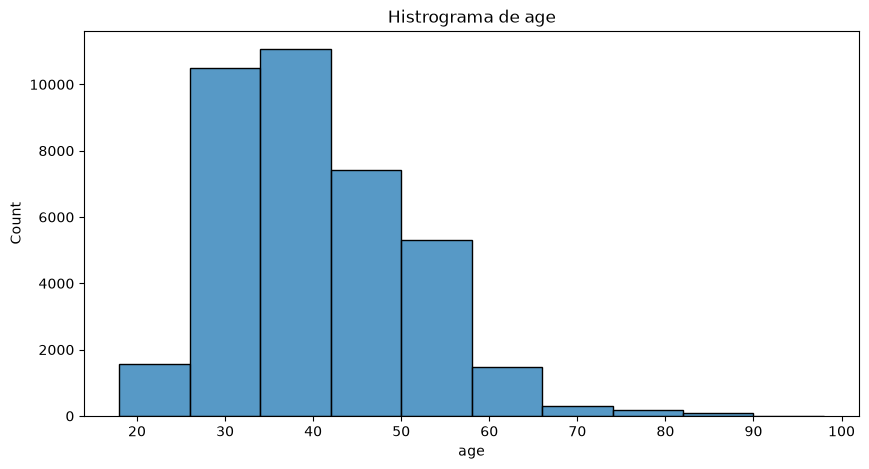

In [195]:
plt.figure(figsize=(10,5))
sns.histplot(df_bc['age'], bins=10)
plt.title(f'Histrograma de age')
plt.show()

#### `job`

In [196]:
(df_bc['job']).value_counts(dropna=False)

job
admin.           9564
blue-collar      8489
technician       6228
services         3627
management       2696
retired          1580
entrepreneur     1356
self-employed    1297
housemaid         990
unemployed        945
student           801
NaN               302
Name: count, dtype: int64

In [197]:
df_bc.groupby('job')['age'].min().sort_values()

job
student          18.0
blue-collar      20.0
services         20.0
entrepreneur     20.0
technician       20.0
management       21.0
housemaid        21.0
admin.           21.0
unemployed       21.0
self-employed    21.0
retired          23.0
Name: age, dtype: float64

Observamos que las edades mínimas son bastante lógicas, excepto en `retired`, la cuál es muy raro que haya jubilados de 23 años.

In [198]:
df_bc.groupby('job')['age'].max().sort_values()

job
student          47.0
unemployed       66.0
entrepreneur     69.0
services         69.0
technician       70.0
self-employed    71.0
admin.           72.0
management       80.0
blue-collar      80.0
housemaid        85.0
retired          98.0
Name: age, dtype: float64

En las edades máximas los valores tambíen son lógicos excepto el de `student` con 47, tiene un valor un tanto atípico.

In [199]:
df_bc[df_bc['job'] == 'retired']['age'].value_counts().sort_index().head(20)

age
23.0     1
26.0     1
27.0     1
29.0     1
30.0     1
32.0     1
33.0     2
35.0     5
36.0     6
37.0     4
38.0     2
39.0     4
40.0     3
41.0     1
42.0    11
43.0     4
44.0     5
45.0     5
46.0     4
47.0    14
Name: count, dtype: int64

In [200]:
df_bc.loc[(df_bc['job'] == 'retired') & (df_bc['age'] < 35),
    ['age', 'job', 'marital', 'education', 'housing', 'loan', 'Income', 'y']].sort_values('age')

,age,job,marital,education,housing,loan,Income,y
14880,23.0,retired,SINGLE,professional.course,1.0,0.0,128933,no
36306,26.0,retired,SINGLE,high.school,NaN,NaN,14009,no
13375,27.0,retired,SINGLE,basic.9y,0.0,0.0,162562,no
15880,29.0,retired,SINGLE,basic.4y,0.0,0.0,105317,no
34792,30.0,retired,SINGLE,basic.9y,0.0,0.0,105571,no
1680,32.0,retired,MARRIED,high.school,0.0,0.0,121982,no
30507,33.0,retired,MARRIED,high.school,1.0,0.0,14951,yes
35062,33.0,retired,MARRIED,high.school,1.0,0.0,157476,no


Estos son los clietnes que no tiene sentido que esten `retired`a esas edades

In [201]:
# sacamos del datset los retirados menores de 35 años.
df_bc = df_bc[~((df_bc['job'] == 'retired') & (df_bc['age'] < 35))]

In [202]:
df_bc[((df_bc['job'] == 'student') & (df_bc['age'] > 40))]

,age,job,marital,education,default,housing,loan,contact,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,date,id_,Income,Kidhome,Teenhome,Dt_Customer,NumWebVisitsMonth
17169,46.0,student,SINGLE,NaN,0.0,1.0,0.0,cellular,587,5,999,0,NONEXISTENT,1.4,93.918,-42.7,4.962,5228.1,no,2018-02-17,1c2a6345-eed7-4bae-8bc8-bbd8d58a3198,136802,1,0,2012-07-10,2
17194,46.0,student,SINGLE,NaN,0.0,1.0,0.0,telephone,279,4,999,0,NONEXISTENT,1.4,93.918,-42.7,4.962,5228.1,yes,2016-03-27,65c0c554-063a-4032-b10b-5fbfb1d8bf04,148927,1,2,2012-01-31,1
17927,41.0,student,MARRIED,NaN,NaN,1.0,1.0,cellular,69,5,999,0,NONEXISTENT,1.4,93.918,-42.7,NaN,5228.1,no,2017-08-23,49f086b9-f06e-4a26-8be6-180ccf09f916,19043,2,0,2012-09-13,26
23972,47.0,student,SINGLE,NaN,0.0,NaN,NaN,telephone,145,1,999,0,NONEXISTENT,-0.1,93.200,-42.0,4.406,5195.8,yes,2015-11-07,cc3b9d83-24b7-4d7f-83cd-838e91132fc3,30183,1,1,2013-04-30,29
40835,45.0,student,SINGLE,NaN,0.0,1.0,0.0,cellular,316,2,999,2,FAILURE,-1.1,94.601,-49.5,1.016,4963.6,no,2018-10-01,6a77a3f1-e21a-4c35-a339-e6250be29a89,22079,2,1,2014-10-31,32


Tenemos 5 registros de estudiantes de más de 40 años, es un poco extraño, aunque no imposible. Por lo que los mantendremos en el datset.

#### `marital`

In [203]:
df_bc['marital'].value_counts(dropna=False)

marital
MARRIED     22890
SINGLE      10642
DIVORCED     4258
NaN            77
Name: count, dtype: int64

In [204]:
df_bc["marital"] = df_bc["marital"].str.lower()

La mayoría de los clientes están casados (MARRIED), seguidos de los solteros (SINGLE) y los divorciados (DIVORCED). Se observan 77 valores nulos, una cantidad muy reducida respecto al total de registros. También cambiamos los grupos a minúsculas ya que todas las columnas de datos que tenmos van en minúsucalas.

#### `education`

In [205]:
df_bc['education'].value_counts(dropna=False)

education
university.degree      11261
high.school             8730
basic.9y                5571
professional.course     4833
basic.4y                3836
basic.6y                2087
NaN                     1535
illiterate                14
Name: count, dtype: int64

In [206]:
df_bc['education'].isna().mean() * 100

np.float64(4.053661499458632)

Los nulos en education son un 4,05% del total

In [207]:
df_bc[df_bc['education'] == 'illiterate']

,age,job,marital,education,default,housing,loan,contact,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,date,id_,Income,Kidhome,Teenhome,Dt_Customer,NumWebVisitsMonth
5296,45.0,blue-collar,married,illiterate,NaN,0.0,1.0,telephone,333,2,999,0,NONEXISTENT,1.1,93.994,-36.4,4.857,5191.0,no,2018-06-16,5eb1724a-982c-410b-a6fa-301de45207ba,13017,0,1,2012-03-18,14
6831,45.0,blue-collar,married,illiterate,NaN,0.0,0.0,telephone,1196,1,999,0,NONEXISTENT,1.1,93.994,-36.4,4.860,5191.0,no,2015-02-16,f1c0c3e0-4676-4d4d-acbf-531cd9c761b3,25694,1,2,2012-12-28,13
14348,55.0,blue-collar,married,illiterate,0.0,1.0,0.0,cellular,92,3,999,0,NONEXISTENT,1.4,93.918,-42.7,4.961,5228.1,no,2016-11-18,e603ac8b-60e6-4d9f-bca1-0a191033d3d9,107633,1,1,2012-02-14,10
14389,55.0,blue-collar,married,illiterate,0.0,0.0,0.0,cellular,129,2,999,0,NONEXISTENT,1.4,93.918,-42.7,4.961,5228.1,no,2015-02-28,fe51e1aa-8010-4a94-86d6-3c4f9197b633,113229,1,1,2012-11-22,21
16172,60.0,housemaid,married,illiterate,NaN,1.0,0.0,cellular,176,7,999,0,NONEXISTENT,1.4,93.918,-42.7,NaN,5228.1,no,2017-02-25,ffaf6bb8-4358-4adf-b05d-b4d32502165a,133597,0,0,2012-04-03,3
22305,45.0,blue-collar,married,illiterate,0.0,1.0,0.0,cellular,127,1,999,0,NONEXISTENT,1.4,93.444,-36.1,4.964,5228.1,no,2015-03-21,027cdf51-50ba-4bb8-bbed-486da014bdcf,100319,2,0,2013-03-23,31
22545,44.0,blue-collar,married,illiterate,0.0,0.0,0.0,cellular,460,1,999,0,NONEXISTENT,1.4,93.444,-36.1,4.964,5228.1,no,2017-06-28,8af632f4-018c-4ff1-9a3d-349eb232e2b2,119283,1,0,2013-06-24,17
26558,34.0,self-employed,married,illiterate,0.0,1.0,0.0,cellular,51,1,999,0,NONEXISTENT,-0.1,93.200,-42.0,4.076,5195.8,no,2016-01-20,7b30f0af-91ee-45b3-b776-6f63b53a456e,94691,2,0,2013-12-26,19
26567,34.0,self-employed,married,illiterate,0.0,1.0,0.0,cellular,488,1,999,0,NONEXISTENT,-0.1,93.200,-42.0,4.076,5195.8,yes,2018-09-27,6c06f00b-4ec1-41c3-bdf7-c159083a4dd9,25397,0,0,2013-07-15,20
28483,51.0,entrepreneur,married,illiterate,0.0,1.0,0.0,cellular,838,3,999,0,NONEXISTENT,-1.8,93.075,-47.1,1.410,5099.1,yes,2019-01-05,8a5e9aed-1477-4f5d-a48e-576b57131aa1,26732,0,0,2013-09-30,8


Los registros de illiterate, son totalmente normales. Pero al ser tan pocos llaman un poco la atención.

#### `default`

In [208]:
df_bc['default'].value_counts(dropna=False)

default
0.0    29990
NaN     7875
1.0        2
Name: count, dtype: int64

In [209]:
df_bc[df_bc['default'] == 1]

,age,job,marital,education,default,housing,loan,contact,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,date,id_,Income,Kidhome,Teenhome,Dt_Customer,NumWebVisitsMonth
21483,48.0,technician,married,professional.course,1.0,0.0,0.0,cellular,66,1,999,0,NONEXISTENT,1.4,93.444,-36.1,4.963,5228.1,no,2015-12-14,3a48bd5f-9c6f-4ebc-ba8d-ab79a142a137,33112,0,0,2013-08-25,28
21484,48.0,technician,married,professional.course,1.0,1.0,0.0,cellular,133,1,999,0,NONEXISTENT,1.4,93.444,-36.1,4.963,5228.1,no,2019-09-05,24897023-f06b-4c57-b445-c91675846025,144251,2,1,2013-06-26,3


Los 2 regitros con impagos son totalmente normales.

In [210]:
df_bc['default'].isna().mean() * 100

np.float64(20.796471862043468)

Tenemos 7875 nulos en default que son el 20,8% un número bastante significativo, tendremos que ver como tratar esos nulos.

#### `housing`

In [211]:
df_bc['housing'].value_counts(dropna=False)

housing
1.0    19838
0.0    17117
NaN      912
Name: count, dtype: int64

In [212]:
df_bc['housing'].isna().mean() * 100

np.float64(2.408429503261415)

Hay bastante pariedad en los registros de clientes con y sin hipoteca. Los registros nulos no son un porcentaje muy alto 2,4%.

#### `loan`

In [213]:
df_bc['loan'].value_counts(dropna=False)

loan
0.0    31196
1.0     5759
NaN      912
Name: count, dtype: int64

In [214]:
df_bc['loan'].isna().mean() * 100

np.float64(2.408429503261415)

La mayoría de clientes no tienen creditos, y aparecen 912 registros nulos que equivalen al 2,4%.

#### `contact`

In [215]:
df_bc['contact'].value_counts(dropna=False)

contact
cellular     24110
telephone    13757
Name: count, dtype: int64

#### `duration`

In [216]:
df_bc['duration'].describe().round(2)

count    37867.00
mean       258.07
std        259.59
min          0.00
25%        102.00
50%        179.00
75%        320.00
max       4918.00
Name: duration, dtype: float64

In [217]:
df_bc['duration'].value_counts().sort_index().head(10)

duration
0     4
1     3
2     1
3     4
4    10
5    29
6    35
7    44
8    63
9    67
Name: count, dtype: int64

In [218]:
df_bc['duration'].value_counts().sort_index().tail(10)

duration
3183    1
3322    1
3366    1
3422    1
3509    1
3631    1
3643    1
3785    1
4199    1
4918    2
Name: count, dtype: int64

La variable no presenta valores nulos. Las duraciones más bajas son poco frecuentes, con solo 4 registros de 0 segundos. En el extremo superior también se observan valores aislados, llegando hasta 4.918 segundos, que aparece en 2 registros. Estos valores extremos se mantienen, ya que no se puede determinar que sean errores y serán considerados en el análisis posterior de la distribución.

#### `campaign`

In [219]:
df_bc['campaign'].describe().round(2)

count    37867.00
mean         2.57
std          2.79
min          1.00
25%          1.00
50%          2.00
75%          3.00
max         56.00
Name: campaign, dtype: float64

La variable no presenta valores nulos y registra una media de 2,57 contactos por cliente, con una mediana de 2. La mayoría de los registros se concentra entre 1 y 3 contactos, mientras que el valor máximo alcanza los 56 contactos, por lo que se revisarán los valores más elevados para comprobar la existencia de posibles valores extremos.

In [220]:
df_bc['campaign'].value_counts().sort_index().tail(10)

campaign
33    4
34    3
35    5
37    1
39    1
40    2
41    1
42    2
43    2
56    1
Name: count, dtype: int64

Se observan algunos valores elevados, aunque son poco frecuentes, siendo 56 contactos el valor máximo y aparece únicamente en un registro. Estos valores se mantienen al no poder determinarse que sean errores, aunque se tendrán en cuenta como posibles valores extremos en el análisis posterior.

#### `pdays`

In [221]:
df_bc['pdays'].value_counts(dropna=False)

pdays
999    36474
3        410
6        374
4         99
9         61
7         55
2         52
12        52
10        49
5         44
13        34
11        26
15        26
1         21
14        20
8         18
0         14
16        12
17         9
18         4
22         4
19         3
21         2
25         1
26         1
27         1
20         1
Name: count, dtype: int64

La variable indica el número de días transcurridos desde el último contacto realizado al cliente. Se observa que el valor 999 aparece en 36.474 registros, representando la gran mayoría de los datos. Este valor no corresponde a 999 días, sino que se utiliza para indicar que el cliente no había sido contactado previamente.

Para evitar que este valor interfiera en los cálculos y análisis de la variable numérica, se sustituye 999 por NaN.
Además, se crea una nueva variable previously_contacted para conservar la información de si el cliente había sido contactado anteriormente.

In [222]:
# Sustituimos 999 por NaN porque indica que no había sido contactado anteriormente
df_bc['pdays'] = df_bc['pdays'].replace(999, np.nan)

# Creamos una variable para identificar si había sido contactado anteriormente
df_bc['previously_contacted'] = df_bc['pdays'].notna()

In [223]:
df_bc['pdays'].value_counts(dropna=False)

pdays
NaN     36474
3.0       410
6.0       374
4.0        99
9.0        61
7.0        55
2.0        52
12.0       52
10.0       49
5.0        44
13.0       34
11.0       26
15.0       26
1.0        21
14.0       20
8.0        18
0.0        14
16.0       12
17.0        9
18.0        4
22.0        4
19.0        3
21.0        2
25.0        1
26.0        1
27.0        1
20.0        1
Name: count, dtype: int64

In [224]:
df_bc['previously_contacted'].value_counts()

previously_contacted
False    36474
True      1393
Name: count, dtype: int64

Comprovamos que 36474 clientes no habían sido contactados previamente.

#### `previous`

In [225]:
df_bc['previous'].value_counts(dropna=False)

previous
0    32690
1     4200
2      689
3      204
4       63
5       16
6        4
7        1
Name: count, dtype: int64

#### `poutcome`

In [226]:
df_bc['poutcome'].value_counts(dropna=False)

poutcome
NONEXISTENT    32690
FAILURE         3916
SUCCESS         1261
Name: count, dtype: int64

In [227]:
df_bc["poutcome"] = df_bc["poutcome"].str.lower()  

In [228]:
df_bc["poutcome"].head()

1    nonexistent
2    nonexistent
3    nonexistent
4    nonexistent
5    nonexistent
Name: poutcome, dtype: str

pasamos a lower las categrorias de la variable.

#### `emp.var.rate`

In [229]:
df_bc['emp.var.rate'].value_counts(dropna=False)

emp.var.rate
 1.4    14966
-1.8     8447
 1.1     7076
-0.1     3363
-2.9     1539
-3.4      987
-1.7      731
-1.1      585
-3.0      163
-0.2       10
Name: count, dtype: int64

In [230]:
df_bc['emp.var.rate'].describe().round(2)

count    37867.00
mean         0.08
std          1.57
min         -3.40
25%         -1.80
50%          1.10
75%          1.40
max          1.40
Name: emp.var.rate, dtype: float64

#### `cons.price.idx`

In [231]:
df_bc['cons.price.idx'].value_counts(dropna=False)

cons.price.idx
93.994    6999
93.918    6101
92.893    5252
93.444    4722
94.465    3991
93.200    3286
93.075    2239
92.201     690
92.963     664
NaN        412
92.431     409
92.649     328
94.215     292
94.199     276
92.843     268
93.369     239
92.379     238
94.027     218
94.055     208
93.876     199
94.601     185
92.469     169
92.713     161
93.749     158
94.767     118
93.798      35
92.756      10
Name: count, dtype: int64

In [232]:
df_bc['cons.price.idx'].describe().round(2)

count    37455.00
mean        93.58
std          0.58
min         92.20
25%         93.08
50%         93.75
75%         93.99
max         94.77
Name: cons.price.idx, dtype: float64

La variable presenta 412 valores nulos. Los valores disponibles se encuentran entre 92,20 y 94,77, con una media de 93,58 y una mediana de 93,75. Se observan valores repetidos con frecuencia, algo esperable al tratarse de un índice económico. 

#### `cons.conf.idx`

In [233]:
df_bc['cons.conf.idx'].value_counts(dropna=False)

cons.conf.idx
-36.4    7076
-42.7    6160
-46.2    5311
-36.1    4771
-41.8    4035
-42.0    3328
-47.1    2263
-31.4     700
-40.8     670
-26.9     414
-30.1     332
-40.3     299
-37.5     278
-50.0     269
-34.8     242
-29.8     241
-38.3     221
-39.8     211
-40.0     200
-49.5     187
-33.6     169
-33.0     163
-34.6     162
-50.8     120
-40.4      35
-45.9      10
Name: count, dtype: int64

In [234]:
df_bc['cons.conf.idx'].describe().round(2)

count    37867.00
mean       -40.51
std          4.63
min        -50.80
25%        -42.70
50%        -41.80
75%        -36.40
max        -26.90
Name: cons.conf.idx, dtype: float64

#### `euribor3m`

In [235]:
df_bc['euribor3m'].value_counts(dropna=False)

euribor3m
NaN      8082
4.857    2024
4.962    1891
4.963    1763
4.961    1390
         ... 
0.895       1
0.894       1
0.953       1
0.956       1
1.047       1
Name: count, Length: 309, dtype: int64

In [236]:
df_bc['euribor3m'].describe().round(2)

count    29785.00
mean         3.62
std          1.74
min          0.63
25%          1.34
50%          4.86
75%          4.96
max          5.04
Name: euribor3m, dtype: float64

In [237]:
df_bc['euribor3m'].isna().mean() * 100

np.float64(21.34312197956004)

La variable presenta 8.082 valores nulos, aproximadamente un 21,4% del total, por lo que se trata de una cantidad significativa de datos faltantes. Los valores disponibles se encuentran entre 0,63 y 5,04, sin observarse valores claramente anómalos. La media es de 3,62, mientras que la mediana es de 4,86, debido a la concentración de valores alrededor de 4,8-5 y a la presencia de valores más bajos. Los valores válidos se mantienen y los nulos se conservarán para valorar posteriormente el tratamiento más adecuado.

#### `nr.employed`

In [238]:
df_bc['nr.employed'].value_counts(dropna=False)

nr.employed
5228.1    14966
5099.1     7843
5191.0     7076
5195.8     3363
5076.2     1539
5017.5      987
4991.6      731
5008.7      604
4963.6      585
5023.5      163
5176.3       10
Name: count, dtype: int64

In [239]:
df_bc['nr.employed'].describe().round(2)

count    37867.00
mean      5166.87
std         72.46
min       4963.60
25%       5099.10
50%       5191.00
75%       5228.10
max       5228.10
Name: nr.employed, dtype: float64

#### `y`

In [240]:
df_bc['y'].value_counts(dropna=False)

y
no     33604
yes     4263
Name: count, dtype: int64

#### `date`

In [241]:
(df_bc['date']).dt.year.value_counts(dropna=False)

date
2019.0    7581
2018.0    7543
2015.0    7530
2016.0    7504
2017.0    7495
NaN        214
Name: count, dtype: int64

In [242]:
(df_bc['date']).dt.month.value_counts(dropna=False)

date
2.0     3170
9.0     3169
10.0    3165
3.0     3162
11.0    3160
5.0     3148
4.0     3143
7.0     3142
8.0     3131
6.0     3096
1.0     3088
12.0    3079
NaN      214
Name: count, dtype: int64

`date`: La variable recoge fechas comprendidas entre los años **2015 y 2019**. La distribución por año es bastante equilibrada, con alrededor de **8.500 registros por año**, por lo que no parece existir una concentración importante de clientes en un año concreto. En cuanto a los meses, también se observa una distribución bastante uniforme, con valores que van aproximadamente desde **3.500 hasta 3.600 registros por mes**. Por tanto, no se observa a simple vista una concentración significativa de registros en un periodo concreto.

In [243]:
df_bc.loc[df_bc['date'].isna()].sample(10)

,age,job,marital,education,default,housing,loan,contact,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,date,id_,Income,Kidhome,Teenhome,Dt_Customer,NumWebVisitsMonth,previously_contacted
24203,40.0,blue-collar,married,basic.9y,0.0,0.0,0.0,cellular,215,1,NaN,1,failure,-0.1,93.200,-42.0,4.191,5195.8,no,NaT,76aeaf4c-d056-4e48-9cb3-1e7aced583fb,27492,0,1,2013-01-04,1,False
39923,59.0,retired,divorced,basic.4y,0.0,0.0,0.0,cellular,410,2,NaN,0,nonexistent,-1.7,94.215,-40.3,0.827,4991.6,no,NaT,42ac0289-3ef2-4e3d-b085-508fc9e6e49a,84133,1,0,2014-12-19,3,False
24926,29.0,management,single,university.degree,0.0,0.0,0.0,cellular,232,1,NaN,1,failure,-0.1,93.200,-42.0,NaN,5195.8,no,NaT,f03b408f-0246-4c03-b219-2560cdb00940,127691,0,2,2013-06-14,16,False
20477,56.0,blue-collar,married,NaN,0.0,1.0,0.0,cellular,178,8,NaN,0,nonexistent,1.4,93.444,-36.1,4.966,5228.1,no,NaT,8f904e8b-e88a-4871-971b-a2fabe2ae07d,102673,1,2,2013-10-02,14,False
39100,29.0,admin.,single,high.school,0.0,1.0,1.0,cellular,257,1,NaN,0,nonexistent,-1.8,93.369,-34.8,0.646,5008.7,yes,NaT,e310da42-e9bc-4f7b-87fb-e8dc6f538b95,44418,1,0,2014-01-12,19,False
19028,36.0,admin.,divorced,university.degree,0.0,1.0,0.0,cellular,112,2,NaN,0,nonexistent,1.4,93.444,-36.1,4.968,5228.1,no,NaT,77a188be-d456-44e4-b290-904777d514c7,70302,2,2,2012-06-17,11,False
39381,36.0,admin.,married,NaN,0.0,0.0,0.0,cellular,91,1,NaN,0,nonexistent,-1.8,93.749,-34.6,0.659,5008.7,no,NaT,5d996b3e-3408-464a-8c35-2ca1cc0b7cae,7159,0,0,2014-03-25,12,False
32032,39.0,services,married,high.school,NaN,1.0,1.0,cellular,19,6,NaN,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no,NaT,484ff6cc-68c4-4bea-b11f-5f3e159f7374,171718,0,0,2014-06-10,16,False
24611,50.0,technician,married,professional.course,0.0,0.0,1.0,cellular,166,1,NaN,0,nonexistent,-0.1,93.200,-42.0,NaN,5195.8,no,NaT,7d0a9887-c29b-4bfd-985b-6d272aa191ee,54559,1,2,2013-10-16,26,False
8413,31.0,technician,married,professional.course,0.0,1.0,0.0,telephone,131,2,NaN,0,nonexistent,1.4,94.465,-41.8,4.864,5228.1,no,NaT,1cb57674-cefb-4a12-a9e2-ad5c1042ca62,80934,0,0,2012-04-16,15,False


Los registros que presentan valores nulos en `date` no muestran a simple vista valores anómalos en el resto de variables. Los clientes pertenecen a perfiles diferentes y no se observa un patrón claro que permita relacionar la ausencia de la fecha con una característica concreta del cliente.

#### `id_`

In [244]:
df_bc['id_'].value_counts(dropna=False)

id_
e9d37224-cb6f-4942-98d7-46672963d097    1
3f9f49b5-e410-4948-bf6e-f9244f04918b    1
9991fafb-4447-451a-8be2-b0df6098d13e    1
eca60b76-70b6-4077-80ba-bc52e8ebb0eb    1
d63ede72-0b6d-45b1-8872-385ac6897f65    1
                                       ..
649cf395-b67a-416c-b9ae-3eaf6d3661c5    1
12d4e85c-39d9-4193-a27d-a58e7af15a43    1
0490dbb9-e21d-4b59-a402-93756e8f17da    1
d9f2c31c-7623-44df-9240-b4514bf21abd    1
0f0aca88-4088-4fe2-905f-44fb675d9493    1
Name: count, Length: 37867, dtype: int64

#### `Income`

In [245]:
df_bc['Income'].describe().round(2)

count     37867.00
mean      93447.70
std       50509.63
min        5841.00
25%       49728.50
50%       93316.00
75%      136935.00
max      180802.00
Name: Income, dtype: float64

#### `Kidhome`

In [246]:
df_bc['Kidhome'].describe().round(2)

count    37867.00
mean         1.00
std          0.82
min          0.00
25%          0.00
50%          1.00
75%          2.00
max          2.00
Name: Kidhome, dtype: float64

#### `Teenhome`

In [247]:
df_bc['Teenhome'].describe().round(2)

count    37867.00
mean         1.00
std          0.82
min          0.00
25%          0.00
50%          1.00
75%          2.00
max          2.00
Name: Teenhome, dtype: float64

In [248]:
df_bc[['Kidhome','Teenhome']].sample(10)

,Kidhome,Teenhome
16136,1,1
21150,2,0
12337,1,1
13555,1,0
15158,0,2
35218,0,2
26561,0,2
42742,2,2
30355,1,1
7493,1,1


#### `Dt_Customer`

In [249]:
df_bc['Dt_Customer'].value_counts(dropna=False)

Dt_Customer
2012-08-10    69
2012-01-11    68
2012-08-13    66
2012-08-11    64
2012-03-21    64
              ..
2013-02-27    12
2013-04-22    12
2013-10-24    11
2013-06-29    11
2013-10-18    10
Name: count, Length: 1096, dtype: int64

In [250]:
(df_bc['Dt_Customer']).dt.year.value_counts(dropna=False)

Dt_Customer
2012    17760
2014    12233
2013     7874
Name: count, dtype: int64

#### `NumWebVisitsMonth`

In [251]:
(df_bc['NumWebVisitsMonth']).value_counts(dropna=False)

NumWebVisitsMonth
14    1258
3     1244
12    1243
32    1241
28    1218
21    1217
29    1216
20    1214
31    1211
15    1202
4     1196
23    1191
9     1187
25    1179
22    1179
13    1178
26    1177
19    1177
10    1176
27    1174
5     1173
30    1173
8     1159
24    1158
6     1158
17    1151
1     1150
11    1149
18    1138
2     1133
16    1128
7     1119
Name: count, dtype: int64

In [252]:
(df_bc['NumWebVisitsMonth']).describe().round(2)

count    37867.00
mean        16.58
std          9.24
min          1.00
25%          9.00
50%         17.00
75%         25.00
max         32.00
Name: NumWebVisitsMonth, dtype: float64

### 3.5 Identificación de nulos

#### Número de valores nulos

Vamos a realizar la identificación de los nulos para ver como serán tratados en el caso de que los haya

In [253]:
nulos_bc = df_bc.isnull().sum().sort_values(ascending = False)
nulos_bc[nulos_bc >0]

pdays             36474
euribor3m          8082
default            7875
education          1535
loan                912
housing             912
cons.price.idx      412
job                 302
date                214
marital              77
dtype: int64

Recordamos que pdays son nulos que hemos creado nosotros mismos para indicar que el cliente que no ha sido contactado.

#### Porcentajes de los valores nulos

Una vez vista la cantidad de nulos en cada variable, vamos a ver el porcentaje de cada uno de ellos para ver reflejado el peso que estos nulso tienen dentro de la variable.

In [254]:
#calculamos el porcentaje de valores nulos por columna
porcentaje_nulos = (df_bc.isnull().mean() * 100)

#mostramos solo las variables que tienen valores nulos
porcentaje_nulos = porcentaje_nulos[porcentaje_nulos > 0].sort_values(ascending=False).round(2)

print(porcentaje_nulos)

pdays             96.32
euribor3m         21.34
default           20.80
education          4.05
loan               2.41
housing            2.41
cons.price.idx     1.09
job                0.80
date               0.57
marital            0.20
dtype: float64


### 3.6 Tratamiento de valores nulos

#### `euribor3m`

In [255]:
df_bc['euribor3m'].isna().sum()

np.int64(8082)

In [256]:
# Resumen estadístico de la variable euribor3m
df_bc['euribor3m'].describe().round(2)

count    29785.00
mean         3.62
std          1.74
min          0.63
25%          1.34
50%          4.86
75%          4.96
max          5.04
Name: euribor3m, dtype: float64

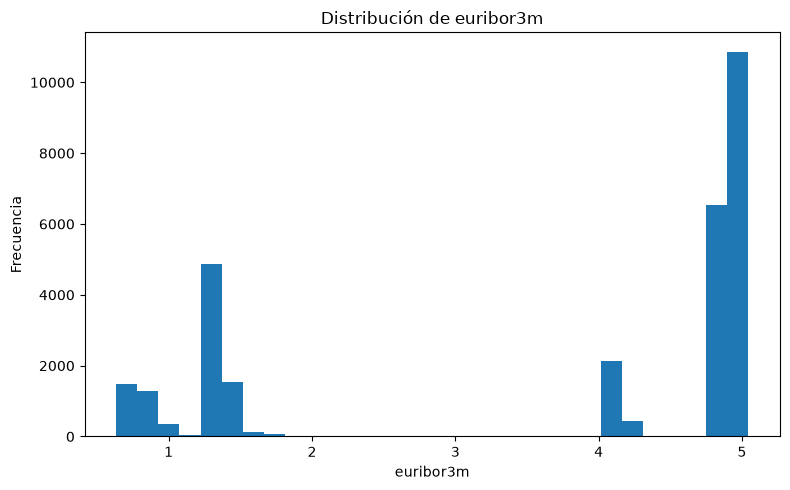

In [257]:
#representamos la distribución de la variable
plt.figure(figsize=(8,5))

plt.hist(df_bc['euribor3m'].dropna(), bins=30)

plt.title('Distribución de euribor3m')
plt.xlabel('euribor3m')
plt.ylabel('Frecuencia')

plt.tight_layout()
plt.show()

La distribución de la variable euribor3m no presenta una forma normal, sino que muestra varios picos de frecuencia, concentrándose la mayor parte en valores cercanos a 5. La diferencia entre la media (3,62) y la mediana (4,86) indica que la distribución está sesgada, por lo que la media no parece ser el mejor estadístico para representar esta variable ni para imputar sus valores nulos.

In [258]:
#vemos si los nulos de euribor3m se concentran en algún año
df_bc.groupby(df_bc['date'].dt.year)['euribor3m'].apply(lambda x: x.isna().sum())

date
2015.0    1639
2016.0    1609
2017.0    1513
2018.0    1581
2019.0    1693
Name: euribor3m, dtype: int64

Hemos analizado los nulos de euribor3m en cada año. Los resultados no muestran los nulos están bastante repartidos entre todos los años. Significa que no hay una cantidad de nulos que afecte a un año determinado, sino que los nulos afectan en general a todo el conjunto del dataset.

In [259]:
pd.crosstab(df_bc['y'],df_bc['euribor3m'].isna(),margins=True)

euribor3m,False,True,All
y,,,
no,26390,7214,33604
yes,3395,868,4263
All,29785,8082,37867


In [260]:
#vamos a comprobar el porcentaje de los nulos

porcentaje_yes = round((999 / 4844) * 100, 2)
porcentaje_no = round((8257 / 38156) * 100, 2)

print(f'Porcentaje de nulos en clientes que contrataron el depósito: {porcentaje_yes}%')
print(f'Porcentaje de nulos en clientes que no contrataron el depósito: {porcentaje_no}%')

Porcentaje de nulos en clientes que contrataron el depósito: 20.62%
Porcentaje de nulos en clientes que no contrataron el depósito: 21.64%


Se puede observar que es muy similar el porcentaje de nulos tanto en los clientes que han contratado el depósito como los que no lo han contratado, por lo tanto, estos nulos no están ligados a si el cliente ha contratado o no un depósito.

**Conclusión**

Tras analizar la distribución de los nulos, observamos que no se concentran en un año concreto ni están relacionados con la contratación del depósito. Por este motivo, decidimos imputar los valores nulos utilizando la mediana. Además, descartamos la media, ya que la distribución de euribor3m no es simétrica y la mediana representa mejor la variable.

In [261]:
#imputamoslos valores nulos de euribor3m con la mediana
df_bc['euribor3m'] = df_bc['euribor3m'].fillna(df_bc['euribor3m'].median())

print(df_bc['euribor3m'].isna().sum())

0


#### `default`

In [262]:
df_bc['default'].isna().sum()

np.int64(7875)

In [263]:
df_bc['default'].value_counts(dropna=False) 

default
0.0    29990
NaN     7875
1.0        2
Name: count, dtype: int64

Solo aparecen dos clientes con impagos, es un número bastante bajo para todo el dataset.

In [264]:
df_bc[df_bc['default'] == 1]

,age,job,marital,education,default,housing,loan,contact,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,date,id_,Income,Kidhome,Teenhome,Dt_Customer,NumWebVisitsMonth,previously_contacted
21483,48.0,technician,married,professional.course,1.0,0.0,0.0,cellular,66,1,NaN,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,no,2015-12-14,3a48bd5f-9c6f-4ebc-ba8d-ab79a142a137,33112,0,0,2013-08-25,28,False
21484,48.0,technician,married,professional.course,1.0,1.0,0.0,cellular,133,1,NaN,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,no,2019-09-05,24897023-f06b-4c57-b445-c91675846025,144251,2,1,2013-06-26,3,False


Vemos que los 2 clientes tienen valores normales, no son ningún caso raro y son datos válidos.

In [265]:
#relación de default con la variable y
pd.crosstab(df_bc['y'], df_bc['default'].isna(), margins=True)

default,False,True,All
y,,,
no,26138,7466,33604
yes,3854,409,4263
All,29992,7875,37867


In [266]:
# Calculamos el porcentaje de nulos de default según la variable objetivo
porcentaje_nulos_default = (df_bc.groupby('y')['default'].apply(lambda x: round(x.isna().mean() * 100, 2)))
print(porcentaje_nulos_default)

y
no     22.22
yes     9.59
Name: default, dtype: float64


Los valores nulos de `default` están repartidos de forma desigual: aparecen en el 22,22 % de los clientes que no contrataron el depósito y en el 9,59 % de los que sí. Como la falta de dato parece relacionada con la variable objetivo, no se imputa con un valor concreto, sino que se mantiene como una categoría propia (`unknown`), para no perder esa información.

In [267]:
#como son los default nulos
df_bc[df_bc['default'].isna()].head()

,age,job,marital,education,default,housing,loan,contact,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,date,id_,Income,Kidhome,Teenhome,Dt_Customer,NumWebVisitsMonth,previously_contacted
1,57.0,services,married,high.school,NaN,0.0,0.0,telephone,149,1,NaN,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,2016-09-14,e9d37224-cb6f-4942-98d7-46672963d097,85477,1,1,2012-12-30,7,False
5,45.0,services,married,basic.9y,NaN,0.0,0.0,telephone,198,1,NaN,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,2015-09-26,d63ede72-0b6d-45b1-8872-385ac6897f65,143854,0,1,2012-01-24,26,False
10,41.0,blue-collar,married,NaN,NaN,0.0,0.0,telephone,55,1,NaN,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,2015-11-30,8d700df5-0c33-4517-8cf8-92e1c92c9c12,92882,1,1,2012-01-05,9,False
15,54.0,retired,married,basic.9y,NaN,1.0,1.0,telephone,174,1,NaN,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,2016-01-03,c93f0774-c122-421b-ac44-2041dcc43609,117422,1,2,2012-04-05,15,False
19,39.0,management,single,basic.9y,NaN,0.0,0.0,telephone,195,1,NaN,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,2017-07-01,74bf1569-4bdb-49e4-98ba-c1c607d90596,173275,2,0,2012-04-17,26,False


In [268]:
#comportamiento de los clientes con default nulo en todas las columnas de datset
df_bc[df_bc['default'].isna()].describe(include='all').round(2)

,age,job,marital,education,default,housing,loan,contact,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,date,id_,Income,Kidhome,Teenhome,Dt_Customer,NumWebVisitsMonth,previously_contacted
count,7875.00,7742,7865,7394,0.0,7666.00,7666.00,7875,7875.00,7875.00,54.00,7875.00,7875,7875.00,7793.00,7875.00,7875.00,7875.00,7875,7840,7875,7875.00,7875.00,7875.00,7875,7875.00,7875
unique,NaN,11,3,7,NaN,NaN,NaN,2,NaN,NaN,NaN,NaN,3,NaN,NaN,NaN,NaN,NaN,2,NaN,7875,NaN,NaN,NaN,NaN,NaN,2
top,NaN,blue-collar,married,basic.4y,NaN,NaN,NaN,cellular,NaN,NaN,NaN,NaN,nonexistent,NaN,NaN,NaN,NaN,NaN,no,NaN,e9d37224-cb6f-4942-98d7-46672963d097,NaN,NaN,NaN,NaN,NaN,False
freq,NaN,2911,5737,1562,NaN,NaN,NaN,4021,NaN,NaN,NaN,NaN,7365,NaN,NaN,NaN,NaN,NaN,7466,NaN,1,NaN,NaN,NaN,NaN,NaN,7821
mean,43.37,NaN,NaN,NaN,NaN,0.52,0.15,NaN,252.83,2.75,5.70,0.07,NaN,0.71,93.76,-40.27,4.40,5193.96,NaN,2017-06-24 18:51:14.693877,NaN,92887.57,1.01,1.00,2013-01-09 08:09:30.514285,16.56,NaN
min,19.00,NaN,NaN,NaN,NaN,0.00,0.00,NaN,5.00,1.00,0.00,0.00,NaN,-3.40,92.20,-50.00,0.64,4963.60,NaN,2015-01-01 00:00:00,NaN,5877.00,0.00,0.00,2012-01-01 00:00:00,1.00,NaN
25%,36.00,NaN,NaN,NaN,NaN,0.00,0.00,NaN,99.00,1.00,3.00,0.00,NaN,1.10,93.44,-42.70,4.86,5191.00,NaN,2016-03-29 18:00:00,NaN,49544.50,0.00,0.00,2012-05-21 00:00:00,9.00,NaN
50%,43.00,NaN,NaN,NaN,NaN,1.00,0.00,NaN,175.00,2.00,6.00,0.00,NaN,1.40,93.92,-41.80,4.86,5228.10,NaN,2017-06-23 00:00:00,NaN,92791.00,1.00,1.00,2012-10-05 00:00:00,17.00,NaN
75%,50.00,NaN,NaN,NaN,NaN,1.00,0.00,NaN,314.00,3.00,6.75,0.00,NaN,1.40,93.99,-36.40,4.96,5228.10,NaN,2018-09-24 00:00:00,NaN,136239.50,2.00,2.00,2013-07-27 12:00:00,25.00,NaN
max,98.00,NaN,NaN,NaN,NaN,1.00,1.00,NaN,3366.00,56.00,15.00,4.00,NaN,1.40,94.60,-26.90,4.97,5228.10,NaN,2019-12-31 00:00:00,NaN,180787.00,2.00,2.00,2014-12-31 00:00:00,32.00,NaN


In [269]:
df_bc['default'] = df_bc['default'].map({1.0: 'yes', 0.0: 'no'}).fillna('unknown')

In [270]:
df_bc['default'].value_counts()

default
no         29990
unknown     7875
yes            2
Name: count, dtype: int64

pasamos 0 y 1 a 'yes' y 'no' para poner los nulos como 'unknown'

#### `age`

>Nota de revisión. 
El filtro age >= 18, del apartado `age` en el apartado 3.4 Inspección de columnas, elimina los 5 menores de edad, pero también descarta los 5.120 clientes sin edad registrada, porque un valor vacío no cumple la condición. Este efecto no estaba previsto al escribir el filtro. Una vez terminado el análisis, se ha comprobado si esa decisión podía influir en los resultados comparando, en los datos originales, la tasa de contratación de los clientes con y sin edad: 11,26 % frente a 11,29 %. Al ser prácticamente iguales, descartarlos no altera la tasa base ni el comportamiento que se estudia, por lo que se mantiene la decisión de no imputar una edad que no conocemos. La comprobación se ha hecho en el apartado 3.4 Inspección de columnas.

In [271]:
df_bc['age'].isna().sum()

np.int64(0)

#### `education`

In [272]:
df_bc['education'].isna().sum()

np.int64(1535)

In [273]:
df_bc['education'].value_counts(dropna=False)

education
university.degree      11261
high.school             8730
basic.9y                5571
professional.course     4833
basic.4y                3836
basic.6y                2087
NaN                     1535
illiterate                14
Name: count, dtype: int64

In [274]:
#porcentaje de cada categoría de education
nulos_education = df_bc['education'].value_counts(normalize=True, dropna=False) * 100
nulos_education.round(2)

education
university.degree      29.74
high.school            23.05
basic.9y               14.71
professional.course    12.76
basic.4y               10.13
basic.6y                5.51
NaN                     4.05
illiterate              0.04
Name: proportion, dtype: float64

La categoría más frecuente es university.degree (29,74 %), seguida de high.school (23,05 %). El resto de categorías tienen porcentajes inferiores, siendo illiterate la que menos porcentaje tiene (0,04 %). La variable education tiene un 4,05 % de valores nulos, por lo que es necesario estudiar la mejor estrategia de imputación antes de continuar con el análisis.

In [275]:
# job de los nulos en education
df_bc.loc[df_bc['education'].isna(), 'job'].value_counts(dropna=False)

job
blue-collar      406
admin.           224
technician       185
student          147
services         133
NaN              116
management       105
retired           87
entrepreneur      55
housemaid         37
self-employed     23
unemployed        17
Name: count, dtype: int64

In [276]:
pd.crosstab(df_bc['job'],df_bc['education'],normalize='index').round(2) * 100

education,basic.4y,basic.6y,basic.9y,high.school,illiterate,professional.course,university.degree
job,,,,,,,
admin.,1.0,1.0,5.0,33.0,0.0,3.0,57.0
blue-collar,26.0,16.0,41.0,10.0,0.0,5.0,1.0
entrepreneur,10.0,5.0,15.0,17.0,0.0,9.0,44.0
housemaid,46.0,8.0,9.0,17.0,0.0,6.0,14.0
management,4.0,3.0,6.0,10.0,0.0,3.0,74.0
retired,37.0,5.0,9.0,16.0,0.0,15.0,18.0
self-employed,7.0,2.0,16.0,8.0,0.0,12.0,55.0
services,3.0,6.0,10.0,70.0,0.0,6.0,5.0
student,4.0,2.0,14.0,50.0,0.0,6.0,24.0


Con la tabla anterior, se puede ver una relación entre la profesión y el nivel educativo. Algunas profesiones concentran mayoritariamente un determinado nivel de estudios, como management, donde el 74 % de los clientes tiene estudios universitarios, technician, donde predomina professional.course con 51 %, o services, donde el 70 % de los clientes tiene high.school. Por este motivo, la profesión se considera una buena variable para imputar los valores nulos de education.

In [277]:
#para cada profesión calculamos su educación más frecuente
for job in df_bc['job'].dropna().unique():
    # filtramos los clientes de esa profesión
    mask_job = df_bc['job'] == job
    # calculamos la moda de education para esa profesión
    moda = df_bc.loc[mask_job, 'education'].mode()[0]
    # rellenamos los nulos de education solo para esa profesión
    mask_nulos = mask_job & df_bc['education'].isna()
    df_bc.loc[mask_nulos, 'education'] = moda

print(f"Nulos en education: {df_bc['education'].isna().sum()}")

Nulos en education: 116


In [278]:
df_bc['education'] = df_bc['education'].fillna('unknown')

In [279]:
df_bc['education'].value_counts()

education
university.degree      11668
high.school             9027
basic.9y                5977
professional.course     5018
basic.4y                3960
basic.6y                2087
unknown                  116
illiterate                14
Name: count, dtype: int64

Se han imputado los valores nulos de education utilizando la moda del nivel educativo de cada profesión. La lógica se basa en la relación observada en la tabla cruzada, donde cada profesión concentra mayoritariamente un nivel educativo concreto.Los 116 nulos de los cuales no conocemos `job` los imputamos como unknown.

#### `job`

In [280]:
df_bc['job'].isna().sum()

np.int64(302)

In [281]:
df_bc['job'].value_counts(dropna=False)

job
admin.           9564
blue-collar      8489
technician       6228
services         3627
management       2696
retired          1572
entrepreneur     1356
self-employed    1297
housemaid         990
unemployed        945
student           801
NaN               302
Name: count, dtype: int64

In [282]:
#porcentaje de cada categoría de job
nulos_job = df_bc['job'].value_counts(normalize=True, dropna=False) * 100
nulos_job.round(2)

job
admin.           25.26
blue-collar      22.42
technician       16.45
services          9.58
management        7.12
retired           4.15
entrepreneur      3.58
self-employed     3.43
housemaid         2.61
unemployed        2.50
student           2.12
NaN               0.80
Name: proportion, dtype: float64

Como se observa, admin. es la profesión más frecuente con un 25,26% seguida de blue-collar con 22,42%. Los nulos represnetan un 0.8% del total. A continuación vamos a ver si los clientes con job nulo están relacionados con la contratación o no de un depósito.

In [283]:
pd.crosstab(df_bc['y'], df_bc['job'].isna(), margins=True)

job,False,True,All
y,,,
no,33336,268,33604
yes,4229,34,4263
All,37565,302,37867


Los valores nulos de job se distribuyen prácticamente igual entre los clientes que contrataron el depósito y los que no. Esto indica que los nulos no parecen estar relacionados con la variable objetivo (y), por lo que no existe evidencia de que sigan un patrón específico.

In [284]:
df_bc.loc[df_bc['job'].isna(),'education'].value_counts(dropna=False)


education
unknown                116
basic.4y                50
university.degree       43
high.school             34
basic.9y                29
basic.6y                18
professional.course     12
Name: count, dtype: int64

In [285]:
percent_job = df_bc.loc[df_bc['job'].isna(), 'education'].value_counts(dropna=False, normalize=True) * 100
percent_job.round(2)

education
unknown                38.41
basic.4y               16.56
university.degree      14.24
high.school            11.26
basic.9y                9.60
basic.6y                5.96
professional.course     3.97
Name: proportion, dtype: float64

In [286]:
porcentaje_job_edu = pd.crosstab(df_bc['education'],df_bc['job'],normalize='index')*100

porcentaje_job_edu.round(2)

job,admin.,blue-collar,entrepreneur,housemaid,management,retired,self-employed,services,student,technician,unemployed
education,,,,,,,,,,,
basic.4y,1.76,54.25,3.20,12.20,2.43,16.39,2.23,2.99,0.61,1.25,2.69
basic.6y,6.62,62.49,3.09,3.62,3.48,3.24,1.21,10.00,0.58,4.16,1.50
basic.9y,7.53,63.15,3.23,1.41,2.54,2.30,3.45,6.05,1.51,6.07,2.76
high.school,33.85,8.93,2.52,1.85,3.02,2.68,1.12,28.69,5.29,9.02,3.02
illiterate,0.00,50.00,7.14,7.14,0.00,21.43,14.29,0.00,0.00,0.00,0.00
professional.course,6.47,8.51,2.46,1.06,1.64,4.31,3.14,4.10,0.80,64.88,2.64
university.degree,47.67,0.71,5.37,1.15,17.41,2.30,6.19,1.36,1.37,14.39,2.07


Se estudió la relación entre el nivel educativo y la profesión para comprobar si era posible imputar los valores nulos de job. Aunque algunas categorías educativas presentan una profesión predominante, la relación no es lo suficientemente fuerte como para asignar una profesión con un grado de confianza elevado.

Decisión de imputación:

Dado que los valores nulos representan únicamente el 0,80 % del conjunto de datos y no existe una variable que permita imputarlos con suficiente fiabilidad, se ha decidido mantener estos registros `unknown` para evitar introducir información que no pueda justificarse.

In [287]:
df_bc['job'] = df_bc['job'].fillna('unknown')

In [288]:
df_bc['job'].value_counts()

job
admin.           9564
blue-collar      8489
technician       6228
services         3627
management       2696
retired          1572
entrepreneur     1356
self-employed    1297
housemaid         990
unemployed        945
student           801
unknown           302
Name: count, dtype: int64

#### `housing` y `loan`

Como se podrá ver un poco más adelante, se va a tratar estas dos variables juntas porque coincide que cuando housing es nulo, default es nulo. Se va a trabajar solo con una de las variables, porque los resultados serían los mismos para la otra variable.

In [289]:
df_bc['housing'].isna().sum()

np.int64(912)

In [290]:
df_bc['loan'].isna().sum()

np.int64(912)

In [291]:
df_bc.loc[df_bc['housing'].isna(),'loan'].value_counts(dropna= False)


loan
NaN    912
Name: count, dtype: int64

In [292]:
df_bc.loc[df_bc['loan'].isna(), 'housing'].value_counts(dropna=False)

housing
NaN    912
Name: count, dtype: int64

In [293]:
housing_y = pd.crosstab(df_bc['housing'].isna(), df_bc['y'], normalize='index') * 100

housing_y.round(2)

y,no,yes
housing,,
False,88.72,11.28
True,89.80,10.20


Los valores nulos de housing y loan no parecen estar relacionados con la contratación del depósito (y), ya que la distribución es prácticamente idéntica a la del resto de registros.

In [294]:
df_bc.loc[df_bc['housing'].isna(), 'marital'].value_counts(dropna=False)

marital
married     545
single      255
divorced    111
NaN           1
Name: count, dtype: int64

In [295]:
df_bc.loc[df_bc['housing'].isna(), 'job'].value_counts(dropna=False)

job
blue-collar      216
admin.           205
technician       142
services          96
management        64
retired           42
self-employed     38
entrepreneur      35
housemaid         26
unemployed        23
student           20
unknown            5
Name: count, dtype: int64

In [296]:
pd.crosstab(df_bc['job'],df_bc['housing'],normalize='index').round(2) * 100

housing,0.0,1.0
job,,
admin.,46.0,54.0
blue-collar,47.0,53.0
entrepreneur,45.0,55.0
housemaid,47.0,53.0
management,48.0,52.0
retired,46.0,54.0
self-employed,46.0,54.0
services,47.0,53.0
student,45.0,55.0


In [297]:
df_bc.groupby('housing')['age'].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
housing,,,,,,,,
0.0,17117.0,39.99,10.33,18.0,32.0,38.0,47.0,95.0
1.0,19838.0,39.98,10.52,18.0,32.0,38.0,47.0,98.0


- `age`: También se ha analizado la edad como posible variable para imputar los valores nulos de `housing` y `loan`. Las distribuciones de edad de los clientes con y sin hipoteca son prácticamente iguales, con una media de 39,78 años para los clientes sin hipoteca y 39,74 para los que sí tienen. Por tanto, la edad no parece aportar información suficiente para decidir si un cliente tiene una hipoteca.

In [298]:
pd.crosstab(df_bc['education'],df_bc['housing'],normalize='index').round(2) * 100

housing,0.0,1.0
education,,
basic.4y,48.0,52.0
basic.6y,48.0,52.0
basic.9y,47.0,53.0
high.school,47.0,53.0
illiterate,43.0,57.0
professional.course,45.0,55.0
university.degree,45.0,55.0
unknown,41.0,59.0


- `education`: Los valores de los clientes que tienen o no una hipoteca, según su educación también son muy similares.

In [299]:
df_bc.groupby('housing')['Income'].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
housing,,,,,,,,
0.0,17117.0,93368.37,50694.47,5841.0,49680.00,93181.0,136959.0,180791.0
1.0,19838.0,93498.05,50399.78,5848.0,49729.25,93408.0,136947.0,180802.0


Vamos a realizar los quartiles de Income para distribuirlos por categroias, y así filtrar un poco más el income para imputar los valores en Housing.

In [300]:
def quartiles(qua):
    # calculamos los rangos de los 3 quartiles
    q1 = qua.quantile(0.25)
    q2 = qua.quantile(0.50) 
    q3 = qua.quantile(0.75)

    iqr = q3 - q1 #calculamos el IQR interquartilic range

    # límites superior e inferior para detectar vaores atípicos
    min_q = q1 - 1.5*iqr
    max_q = q3 + 1.5*iqr
    
    return q1, q2, q3, min_q, max_q

q1, q2, q3, min_q, max_q = quartiles(df_bc['Income'])

print(f"Q1 (Primer cuartil): {q1}")
print(f"Q2 (Mediana): {q2}")
print(f"Q3 (Tercer cuartil): {q3}")
print(f"Mínimo (Outlier mínimo): {min_q}")
print(f"Máximo (Outlier máximo): {max_q}")

Q1 (Primer cuartil): 49728.5
Q2 (Mediana): 93316.0
Q3 (Tercer cuartil): 136935.0
Mínimo (Outlier mínimo): -81081.25
Máximo (Outlier máximo): 267744.75


In [301]:
def range_income(income):
    if income < min_q:
        return "very low"
    elif income < q1:
        return "low"
    elif income < q2:
        return "medium"
    elif income < q3:
        return "medium-high"
    elif income <= max_q:  # Incluye el límite máximo
        return "high"
    else:  # Todo lo que sea mayor a max_q
        return "very high"

df_bc['income_level'] = df_bc['Income'].apply(range_income)
df_bc.head()

,age,job,marital,education,default,housing,loan,contact,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,date,id_,Income,Kidhome,Teenhome,Dt_Customer,NumWebVisitsMonth,previously_contacted,income_level
1,57.0,services,married,high.school,unknown,0.0,0.0,telephone,149,1,NaN,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,2016-09-14,e9d37224-cb6f-4942-98d7-46672963d097,85477,1,1,2012-12-30,7,False,medium
2,37.0,services,married,high.school,no,1.0,0.0,telephone,226,1,NaN,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,2019-02-15,3f9f49b5-e410-4948-bf6e-f9244f04918b,147233,1,1,2012-02-02,5,False,high
3,40.0,admin.,married,basic.6y,no,0.0,0.0,telephone,151,1,NaN,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,2015-11-29,9991fafb-4447-451a-8be2-b0df6098d13e,121393,1,2,2012-12-21,29,False,medium-high
4,56.0,services,married,high.school,no,0.0,1.0,telephone,307,1,NaN,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,2017-01-29,eca60b76-70b6-4077-80ba-bc52e8ebb0eb,63164,1,2,2012-06-20,20,False,medium
5,45.0,services,married,basic.9y,unknown,0.0,0.0,telephone,198,1,NaN,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,2015-09-26,d63ede72-0b6d-45b1-8872-385ac6897f65,143854,0,1,2012-01-24,26,False,high


Vamos a comprobar el porcentaje de housing en nuestra nueva columna `income_level`

In [302]:
# Crear tabla resumen de frecuencias de 'housing' por 'income_level'
tabla_resumen = (
    df_bc[df_bc['housing'].notnull()]  # Solo los valores no nulos de housing
    .groupby(['income_level', 'housing'])
    .size()  # Contamos las ocurrencias
    .unstack(fill_value=0)  # Unstack para crear una tabla con las columnas de housing
)

tabla_resumen.columns = ['Housing = 0', 'Housing = 1'] #nombre de las columnas
# Calcular porcentajes
tabla_resumen['Housing = 0 (%)'] = (tabla_resumen['Housing = 0'] / (tabla_resumen['Housing = 0'] + tabla_resumen['Housing = 1'])) * 100
tabla_resumen['Housing = 1 (%)'] = (tabla_resumen['Housing = 1'] / (tabla_resumen['Housing = 0'] + tabla_resumen['Housing = 1'])) * 100
print(tabla_resumen)


              Housing = 0  Housing = 1  Housing = 0 (%)  Housing = 1 (%)
income_level                                                            
high                 4284         4961        46.338561        53.661439
low                  4291         4960        46.384175        53.615825
medium               4281         4947        46.391417        53.608583
medium-high          4261         4970        46.159679        53.840321


**Tratamiento de los valores nulos de `housing` y `loan`**

Después de analizar diferentes variables que podrían estar relacionadas con `housing`, no hemos encontrado ninguna que permita determinar de forma suficientemente fiable si un cliente tiene o no una hipoteca.

Las variables `age`, `Income`, `job`,`education` e `income_level` presentan distribuciones muy similares entre los clientes con y sin hipoteca, mientras que `loan` también presenta valores nulos en exactamente los mismos registros.

Por este motivo, se ha decidido poner como 'unknown' los valores nulos de `housing`, evitando realizar una imputación que podría introducir información incorrecta en el conjunto de datos.

Al igual que en la variable `default`, también vamos a cambiar los 0 y 1 por 'yes' y 'no' para poder imputar los nulos como 'unknown'

In [303]:
df_bc['housing'] = df_bc['housing'].map({1.0: 'yes', 0.0: 'no'}).fillna('unknown')
df_bc['loan'] = df_bc['loan'].map({1.0: 'yes', 0.0: 'no'}).fillna('unknown')

In [304]:
df_bc['housing'].value_counts()

housing
yes        19838
no         17117
unknown      912
Name: count, dtype: int64

In [305]:
df_bc['loan'].value_counts()

loan
no         31196
yes         5759
unknown      912
Name: count, dtype: int64

#### `marital`

In [306]:
df_bc['marital'].isna().sum()

np.int64(77)

In [307]:
df_bc['marital'].value_counts(dropna=False)

marital
married     22890
single      10642
divorced     4258
NaN            77
Name: count, dtype: int64

In [308]:
#porcentaje de cada categoría de marital
nulos_marital = df_bc['marital'].value_counts(normalize=True, dropna=False) * 100
nulos_marital.round(2)

marital
married     60.45
single      28.10
divorced    11.24
NaN          0.20
Name: proportion, dtype: float64

In [309]:
pd.crosstab(df_bc['y'], df_bc['marital'].isna(), margins=True)

marital,False,True,All
y,,,
no,33538,66,33604
yes,4252,11,4263
All,37790,77,37867


In [310]:
df_bc.groupby(df_bc['marital'].isna())['age'].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
marital,,,,,,,,
False,37790.0,39.98,10.43,18.0,32.0,38.0,47.0,98.0
True,77.0,40.71,11.26,25.0,32.0,36.0,50.0,66.0


In [311]:
pd.crosstab(df_bc['job'],df_bc['marital'].isna(),normalize='index').round(3) * 100

marital,False,True
job,,
admin.,99.9,0.1
blue-collar,99.8,0.2
entrepreneur,99.8,0.2
housemaid,99.8,0.2
management,99.9,0.1
retired,99.6,0.4
self-employed,99.5,0.5
services,99.9,0.1
student,99.9,0.1


In [312]:
df_bc['total_children'] = df_bc['Kidhome'] + df_bc['Teenhome']

creamos la columna total childrean para sumar todos los hijos de cada cliente y que esté todo en una columna

In [313]:
pd.crosstab(df_bc['total_children'],df_bc['marital'].isna())

marital,False,True
total_children,,
0,4183,12
1,8352,21
2,12566,22
3,8524,17
4,4165,5


Despues de estas observaciones, decidimos imputar los nulos de `marital` con unknown.


In [314]:
df_bc['marital'] = df_bc['marital'].fillna('unknown')

In [315]:
df_bc['marital'].value_counts(dropna=False)

marital
married     22890
single      10642
divorced     4258
unknown        77
Name: count, dtype: int64

#### `date`

como hemos visto anteriormente en la inspección de columnas, las fechas nulas no tienen ningún dato anómalo por lo que decidimos imputarlas como `unknown`

In [316]:
df_bc['date'] = df_bc['date'].fillna('unknown')

In [317]:
df_bc['date'].value_counts(dropna=False)

date
unknown                214
2016-02-28 00:00:00     86
2018-02-28 00:00:00     83
2015-02-28 00:00:00     82
2017-02-28 00:00:00     82
                      ... 
2016-07-02 00:00:00      9
2018-12-17 00:00:00      8
2019-12-21 00:00:00      8
2017-04-04 00:00:00      8
2015-04-14 00:00:00      8
Name: count, Length: 1826, dtype: int64

#### `cons.price.idx`

In [318]:
df_bc['cons.price.idx'].isna().sum()

np.int64(412)

In [319]:
# Resumen estadístico de la variable cons.price.idx
df_bc['cons.price.idx'].describe().round(2)

count    37455.00
mean        93.58
std          0.58
min         92.20
25%         93.08
50%         93.75
75%         93.99
max         94.77
Name: cons.price.idx, dtype: float64

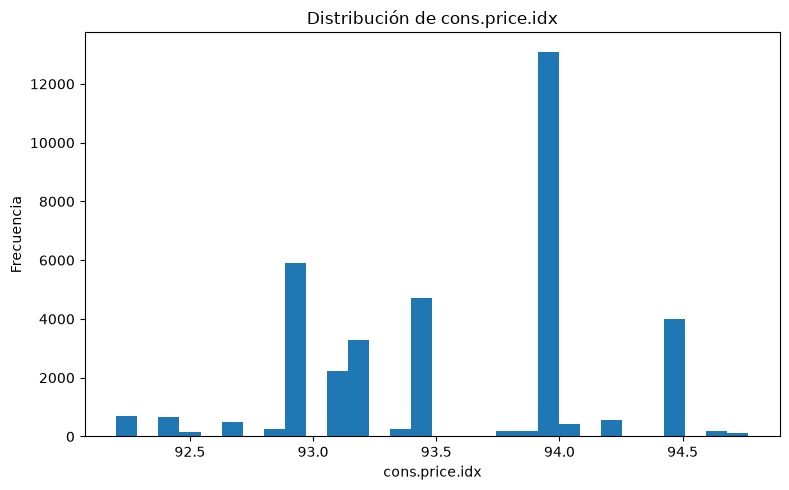

In [320]:
#representamos la distribución de la variable
plt.figure(figsize=(8,5))

plt.hist(df_bc['cons.price.idx'].dropna(), bins=30)

plt.title('Distribución de cons.price.idx')
plt.xlabel('cons.price.idx')
plt.ylabel('Frecuencia')

plt.tight_layout()
plt.show()

El análisis de la variable cons.price.idx muestra una distribución multimodal con concentraciones muy marcadas en valores macroeconómicos específicos (destacando el rango cercano a 94.0). Dado que representa un indicador económico publicado de forma periódica y la cantidad de registros nulos es muy reducida (1.08%), la estrategia óptima de imputación es la imputación por la mediana, evitando así distorsionar la estructura real de precios del periodo.

In [321]:
# Imputación por la mediana
mediana_ipc = df_bc['cons.price.idx'].median()
df_bc['cons.price.idx'] = df_bc['cons.price.idx'].fillna(mediana_ipc)

In [322]:
print(df_bc['cons.price.idx'].isna().sum())

0


## 4. Guardado de datos limpios

In [323]:
df_bc = df_bc.rename(columns={"y": "subscribed"})

cambiamos el nobmre de la columna `y` (si el cliente se ha suscrito o no) por subscribed para que sea más entendible en nuestro datset limpio ya que es la variable objetivo.

In [324]:
df_bc.to_csv('../data/processed/df_bc_limpio.csv', index=False)